# Step Testing Evaluation Rotational Phantom

Content:
1. Load step testing files
2. Visualize Plot
3. Fit the Mathematical Model to the Data
4. Parameter estimation based on the step responses of the controlled system x(t) to a sudden change in the manipulated variable y(t)

In [1]:
import numpy as np
import matplotlib.pyplot as plt # pip install matplotlib==3.7 for tikzplotlib 'https://github.com/nschloe/tikzplotlib/issues/559'
# plt.style.use('ggplot')
# plt.rcParams['axes.facecolor'] = 'white'
# plt.rcParams["font.family"] = ["serif"]
plt.rcParams.update({'font.size': 11})

import csv

from scipy.optimize import curve_fit, minimize
from scipy.stats import zscore

import control
from   control.matlab import *

# import tikzplotlib as tpl

In [2]:
# Tikzplotlib fixes
# For dashed lines: https://github.com/nschloe/tikzplotlib/issues/567
from matplotlib.lines import Line2D
from matplotlib.legend import Legend
Line2D._us_dashSeq    = property(lambda self: self._dash_pattern[1])
Line2D._us_dashOffset = property(lambda self: self._dash_pattern[0])
# Legend._ncol = property(lambda self: self._ncols)

# For legend: https://github.com/nschloe/tikzplotlib/issues/557
def tikzplotlib_fix_ncols(obj):
    """
    workaround for matplotlib 3.6 renamed legend's _ncol to _ncols, which breaks tikzplotlib
    """
    if hasattr(obj, "_ncols"):
        obj._ncol = obj._ncols
    for child in obj.get_children():
        tikzplotlib_fix_ncols(child)

### 0. Step responses in general

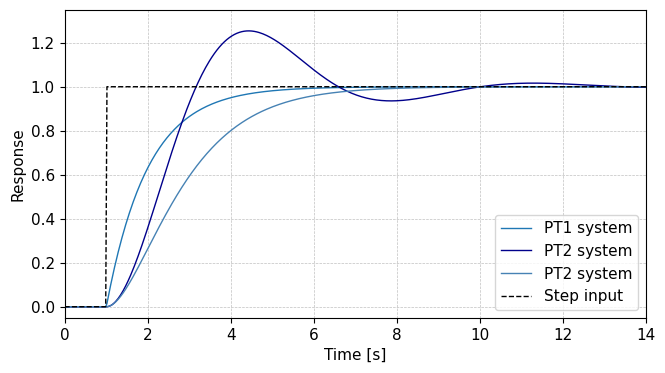

In [3]:
# Define the PT1 system
# Transfer function: H(s) = 1 / (T*s + 1)
T1g = 1  # Time constant for PT1 system
PT1_system = control.TransferFunction([1], [T1g, 1])

# Define the PT2 system
# Transfer function: H(s) = 1 / (T^2*s^2 + 2*ζ*T*s + 1)
T2g = 1  # Natural period
zetag = 0.4  # Damping ratio for PT2 system
PT2_system = control.TransferFunction([1], [T2g**2, 2*zetag*T2g, 1])

T2g2 = 1  # Natural period
zetag2 = 1  # Damping ratio for PT2 system
PT2_system2 = control.TransferFunction([1], [T2g2**2, 2*zetag2*T2g2, 1])

time = np.linspace(0, 15, 500)

# Define input of 1 (step input of magnitude 1)
delay_time = 1  # Step input starts at t = 2 seconds
input_signal = np.where(time >= delay_time, 1, 0)

# Generate step responses
time_PT1, response_PT1= control.forced_response(PT1_system, T=time, U=input_signal)
time_PT2, response_PT2= control.forced_response(PT2_system, T=time, U=input_signal)
time_PT22, response_PT22= control.forced_response(PT2_system2, T=time, U=input_signal)

# Plot of Stepresponses CLOCKWISE
fig2, ax2 = plt.subplots(1, 1, figsize=(7.5, 4))

ax2.plot(time_PT1, response_PT1, label='PT1 system', linewidth=1)
ax2.plot(time_PT2, response_PT2, 'darkblue', label='PT2 system', linewidth=1)
ax2.plot(time_PT22, response_PT22, 'steelblue', label='PT2 system', linewidth=1)
ax2.plot(time, input_signal, 'k--', label='Step input', linewidth=1)

ax2.grid(color='silver', linestyle='--', linewidth=0.5)
ax2.spines['bottom'].set_color('k')
ax2.spines['left'].set_color('k')
ax2.spines['right'].set_color('k')
ax2.spines['top'].set_color('k')
ax2.set_xlim(0, 14)
ax2.set_ylim(-0.05, 1.35)
ax2.legend(loc="lower right")
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Response')

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig2) # call this for legend fix
# tpl.save('tikz/steptest/pt1pt2.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

### 1. Load files

In [4]:
# Paths of csv files
projectpath = r'../../data/steptesting/'
cw36 = projectpath + r'Steptest_Amp36_Nr1CW_240821.csv'
cw38 = projectpath + r'Steptest_Amp38_Nr1CW_240821.csv'
cw39 = projectpath + r'Steptest_Amp39_Nr1CW_240821.csv'
cw40 = projectpath + r'Steptest_Amp40_Nr1CW_240821.csv'
cw42 = projectpath + r'Steptest_Amp42_Nr1CW_240821.csv'
cw44 = projectpath + r'Steptest_Amp44_Nr1CW_240821.csv'

ccw36 = projectpath + r'Steptest_Amp36_Nr1CCW_240821.csv'
ccw38 = projectpath + r'Steptest_Amp38_Nr1CCW_240821.csv'
ccw40 = projectpath + r'Steptest_Amp40_Nr1CCW_240821.csv'
ccw42 = projectpath + r'Steptest_Amp42_Nr1CCW_240821.csv'

In [5]:
## Read csv into arrays (as strings)
## CLOCKWISE
# CW36
rows = []
with open(cw36) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_cw36 = rows[0]
timestamps_cw36 = [float(x) for x in rows[2]]
current_speed_cw36 = [float(x) for x in rows[4]]
setpoint_flow_cw36 = [float(x) for x in rows[6]]
current_flow_cw36 = [float(x) for x in rows[8]]

# CW38
rows = []
with open(cw38) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_cw38 = rows[0]
timestamps_cw38 = [float(x) for x in rows[2]]
current_speed_cw38 = [float(x) for x in rows[4]]
setpoint_flow_cw38 = [float(x) for x in rows[6]]
current_flow_cw38 = [float(x) for x in rows[8]]

# CW39
rows = []
with open(cw39) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_cw39 = rows[0]
timestamps_cw39 = [float(x) for x in rows[2]]
current_speed_cw39 = [float(x) for x in rows[4]]
setpoint_flow_cw39 = [float(x) for x in rows[6]]
current_flow_cw39 = [float(x) for x in rows[8]]

# CW40
rows = []
with open(cw40) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_cw40 = rows[0]
timestamps_cw40 = [float(x) for x in rows[2]]
current_speed_cw40 = [float(x) for x in rows[4]]
setpoint_flow_cw40 = [float(x) for x in rows[6]]
current_flow_cw40 = [float(x) for x in rows[8]]

# CW42
rows = []
with open(cw42) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_cw42 = rows[0]
timestamps_cw42 = [float(x) for x in rows[2]]
current_speed_cw42 = [float(x) for x in rows[4]]
setpoint_flow_cw42 = [float(x) for x in rows[6]]
current_flow_cw42 = [float(x) for x in rows[8]]

# CW44
rows = []
with open(cw44) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_cw44 = rows[0]
timestamps_cw44 = [float(x) for x in rows[2]]
current_speed_cw44 = [float(x) for x in rows[4]]
setpoint_flow_cw44 = [float(x) for x in rows[6]]
current_flow_cw44 = [float(x) for x in rows[8]]

In [6]:
## COUNTERCLOCKWISE
# CcW36
rows = []
with open(ccw36) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_ccw36 = rows[0]
timestamps_ccw36 = [float(x) for x in rows[2]]
current_speed_ccw36 = [float(x) for x in rows[4]]
setpoint_flow_ccw36 = [float(x) for x in rows[6]]
current_flow_ccw36 = [float(x) for x in rows[8]]

# CcW38
rows = []
with open(ccw38) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_ccw38 = rows[0]
timestamps_ccw38 = [float(x) for x in rows[2]]
current_speed_ccw38 = [float(x) for x in rows[4]]
setpoint_flow_ccw38 = [float(x) for x in rows[6]]
current_flow_ccw38 = [float(x) for x in rows[8]]

# CcW40
rows = []
with open(ccw40) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_ccw40 = rows[0]
timestamps_ccw40 = [float(x) for x in rows[2]]
current_speed_ccw40 = [float(x) for x in rows[4]]
setpoint_flow_ccw40 = [float(x) for x in rows[6]]
current_flow_ccw40 = [float(x) for x in rows[8]]

# CcW42
rows = []
with open(ccw42) as file:
    reader = csv.reader(file)
    for row in reader:
        rows.append(row)
# write into lists, convert to floating numbers
names_ccw42 = rows[0]
timestamps_ccw42 = [float(x) for x in rows[2]]
current_speed_ccw42 = [float(x) for x in rows[4]]
setpoint_flow_ccw42 = [float(x) for x in rows[6]]
current_flow_ccw42 = [float(x) for x in rows[8]]

In [7]:
# # print to check
# print(f"List of names: {names_cw40}")
# print(f"List of timestamps: {timestamps_cw40}")
# print(f"List of current_speed: {current_speed_cw40}")
# print(f"List of setpoint_flow: {setpoint_flow_cw40}")
# print(f"List of current_flow: {current_flow_cw40}")

# print shapes
print(f"CW36: names{np.shape(names_cw36)} timestamps{np.shape(timestamps_cw36)} current_speed{np.shape(current_speed_cw36)} setpoint_flow{np.shape(setpoint_flow_cw36)} current_flow{np.shape(current_flow_cw36)}")
print(f"CW38: names{np.shape(names_cw38)} timestamps{np.shape(timestamps_cw38)} current_speed{np.shape(current_speed_cw38)} setpoint_flow{np.shape(setpoint_flow_cw38)} current_flow{np.shape(current_flow_cw38)}")
print(f"CW39: names{np.shape(names_cw39)} timestamps{np.shape(timestamps_cw39)} current_speed{np.shape(current_speed_cw39)} setpoint_flow{np.shape(setpoint_flow_cw39)} current_flow{np.shape(current_flow_cw39)}")
print(f"CW40: names{np.shape(names_cw40)} timestamps{np.shape(timestamps_cw40)} current_speed{np.shape(current_speed_cw40)} setpoint_flow{np.shape(setpoint_flow_cw40)} current_flow{np.shape(current_flow_cw40)}")
print(f"CW42: names{np.shape(names_cw42)} timestamps{np.shape(timestamps_cw42)} current_speed{np.shape(current_speed_cw42)} setpoint_flow{np.shape(setpoint_flow_cw42)} current_flow{np.shape(current_flow_cw42)}")
print(f"CW44: names{np.shape(names_cw44)} timestamps{np.shape(timestamps_cw44)} current_speed{np.shape(current_speed_cw44)} setpoint_flow{np.shape(setpoint_flow_cw44)} current_flow{np.shape(current_flow_cw44)}")
print(f"CCW36: names{np.shape(names_ccw36)} timestamps{np.shape(timestamps_ccw36)} current_speed{np.shape(current_speed_ccw36)} setpoint_flow{np.shape(setpoint_flow_ccw36)} current_flow{np.shape(current_flow_ccw36)}")
print(f"CCW38: names{np.shape(names_ccw38)} timestamps{np.shape(timestamps_ccw38)} current_speed{np.shape(current_speed_ccw38)} setpoint_flow{np.shape(setpoint_flow_ccw38)} current_flow{np.shape(current_flow_ccw38)}")
print(f"CCW40: names{np.shape(names_ccw40)} timestamps{np.shape(timestamps_ccw40)} current_speed{np.shape(current_speed_ccw40)} setpoint_flow{np.shape(setpoint_flow_ccw40)} current_flow{np.shape(current_flow_ccw40)}")
print(f"CCW42: names{np.shape(names_ccw42)} timestamps{np.shape(timestamps_ccw42)} current_speed{np.shape(current_speed_ccw42)} setpoint_flow{np.shape(setpoint_flow_ccw42)} current_flow{np.shape(current_flow_ccw42)}")

CW36: names(4,) timestamps(2386,) current_speed(2386,) setpoint_flow(2386,) current_flow(2386,)
CW38: names(4,) timestamps(2280,) current_speed(2280,) setpoint_flow(2280,) current_flow(2280,)
CW39: names(4,) timestamps(2358,) current_speed(2358,) setpoint_flow(2358,) current_flow(2358,)
CW40: names(4,) timestamps(2132,) current_speed(2132,) setpoint_flow(2132,) current_flow(2132,)
CW42: names(4,) timestamps(2180,) current_speed(2180,) setpoint_flow(2180,) current_flow(2180,)
CW44: names(4,) timestamps(2283,) current_speed(2283,) setpoint_flow(2283,) current_flow(2283,)
CCW36: names(4,) timestamps(2157,) current_speed(2157,) setpoint_flow(2157,) current_flow(2157,)
CCW38: names(4,) timestamps(2039,) current_speed(2039,) setpoint_flow(2039,) current_flow(2039,)
CCW40: names(4,) timestamps(2013,) current_speed(2013,) setpoint_flow(2013,) current_flow(2013,)
CCW42: names(4,) timestamps(2025,) current_speed(2025,) setpoint_flow(2025,) current_flow(2025,)


### 2. Visualize Plot
The plot that is also shown in the GUI is visualized (relevant data).

Text(0, 0.5, 'speed in RPM')

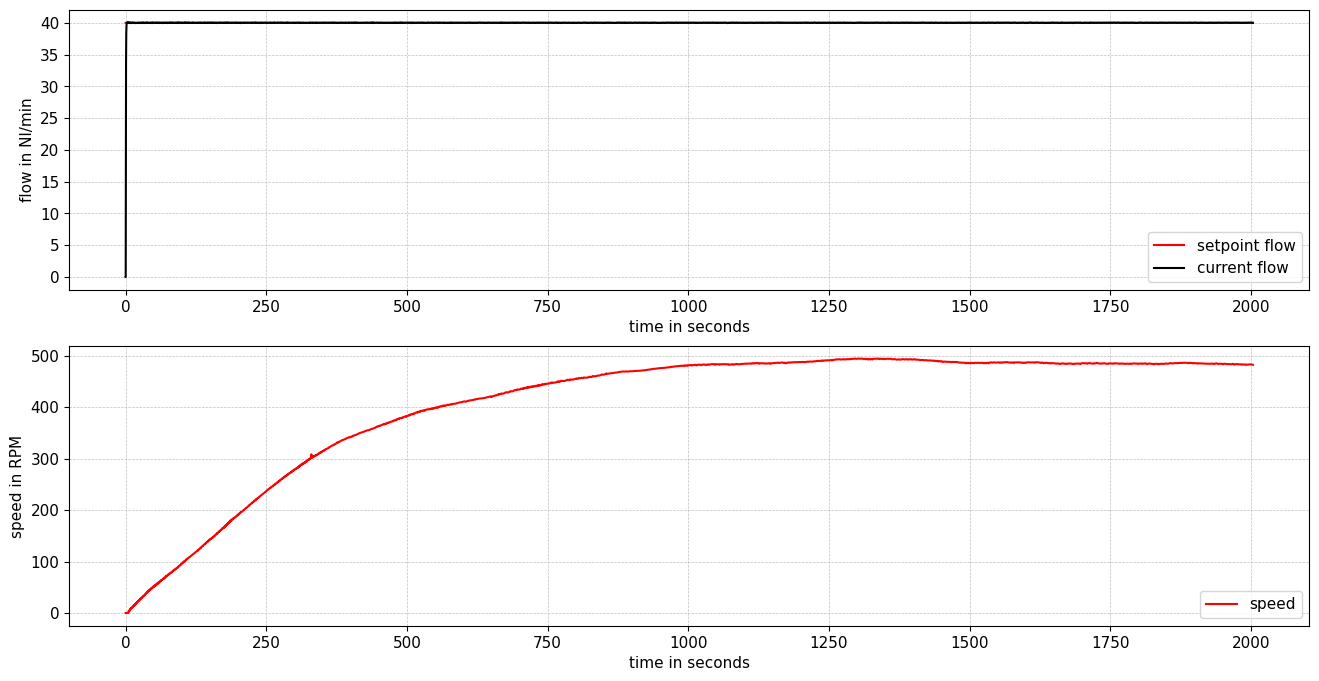

In [8]:
# Flow Control Plot and Speed Plot
fig, ax = plt.subplots(2, 1, figsize=(16, 8))

# Plot
im0 = ax[0].plot(timestamps_cw40, setpoint_flow_cw40[:], 'r', label='setpoint flow')
ax[0].plot(timestamps_cw40, current_flow_cw40, 'k', label='current flow')
ax[0].grid(color='silver', linestyle='--', linewidth=0.5)
ax[0].spines['bottom'].set_color('k')
ax[0].spines['left'].set_color('k')
ax[0].spines['right'].set_color('k')
ax[0].spines['top'].set_color('k')
# ax[0].set_xlim(-5, 200)
# ax[0].set_ylim(-5, 120)
ax[0].legend(loc=4)
ax[0].set_xlabel('time in seconds')
ax[0].set_ylabel('flow in Nl/min')

im1 = ax[1].plot(timestamps_cw40, current_speed_cw40, 'r', label='speed')
ax[1].grid(color='silver', linestyle='--', linewidth=0.5)
ax[1].spines['bottom'].set_color('k')
ax[1].spines['left'].set_color('k')
ax[1].spines['right'].set_color('k')
ax[1].spines['top'].set_color('k')
# ax[1].set_xlim(-5, 200)
ax[1].legend(loc=4)
ax[1].set_xlabel('time in seconds')
ax[1].set_ylabel('speed in RPM')

# # save the plot
# plt.savefig("figs/Steptest_Amp35_Nr1.png")
# # save the plots to tikz files
# tikzplotlib_fix_ncols(fig)
# tpl.save("tikz/Steptest_Amp35_Nr1.tikz")

### 3. System Identification: Fit a Mathematical Model to the Data
The step response graphs show that the system has first-order delay behavior (PT1 system).

The PT1 system step response is of the form:

$y(t)=K(1-e^{-\frac{t}{T}})$

The measured data is cleaned. Then the PT1 model is fitted to the measured data.

In [9]:
# # list to numpy array
# time = np.array(timestamps_cw40)
# response = np.array(current_speed_cw40)

# # Delete outlier using z score method
# # https://stackoverflow.com/questions/77295500/remove-outliers-in-data-keep-the-original-trend
# def outlier_zscore(speed_data, time_data):
#     # set limit on z score
#     z = 2.2
#     time_data = time_data[(np.abs(zscore(speed_data)) < z)]
#     speed_data = speed_data[(np.abs(zscore(speed_data)) < z)]
#     return time_data, speed_data

# # PT1 step response model
# def pt1_step_response(t, K, T):
#     return K * (1 - np.exp(-t / T))

# # Delete outlier data and do the same
# time_clean = outlier_zscore(response, time)[0]
# response_clean = outlier_zscore(response, time)[1]
# params_clean, covariance = curve_fit(pt1_step_response, time_clean, response_clean)
# K_est_clean, T_est_clean = params_clean
# response_ident_clean = pt1_step_response(time_clean, K_est_clean, T_est_clean)

# # Print the estimated parameters
# print(f"Clean Estimated Gain (K):             {K_est_clean}")
# print(f"Clean Estimated Time Constant (T):    {T_est_clean}")

In [10]:
# # Plot Clean (not necessary)
# fig2, ax2 = plt.subplots(1, 1, figsize=(10, 6))

# ax2.plot(time_clean, response_clean, 'k', label='cleaned measured response')
# ax2.plot(time_clean, response_ident_clean, 'r--', label='cleaned fitted response')
# ax2.grid(color='silver', linestyle='--', linewidth=0.5)
# ax2.spines['bottom'].set_color('k')
# ax2.spines['left'].set_color('k')
# ax2.spines['right'].set_color('k')
# ax2.spines['top'].set_color('k')
# # ax.set_xlim(-5, 200)
# # ax.set_ylim(-5, 120)
# ax2.legend(loc=4)
# ax2.set_xlabel('time in s')
# ax2.set_ylabel(r'speed in $\frac{1}{min}$')

In [11]:
# list to numpy array
time_cw36 = np.array(timestamps_cw36)
response_cw36 = np.array(current_speed_cw36)
time_cw38 = np.array(timestamps_cw38)
response_cw38 = np.array(current_speed_cw38)
time_cw39 = np.array(timestamps_cw39)
response_cw39 = np.array(current_speed_cw39)
time_cw40 = np.array(timestamps_cw40)
response_cw40 = np.array(current_speed_cw40)
time_cw42 = np.array(timestamps_cw42)
response_cw42 = np.array(current_speed_cw42)
time_cw44 = np.array(timestamps_cw44)
response_cw44 = np.array(current_speed_cw44)

time_ccw36 = np.array(timestamps_ccw36)
response_ccw36 = np.array(current_speed_ccw36)
time_ccw38 = np.array(timestamps_ccw38)
response_ccw38 = np.array(current_speed_ccw38)
time_ccw40 = np.array(timestamps_ccw40)
response_ccw40 = np.array(current_speed_ccw40)
time_ccw42 = np.array(timestamps_ccw42)
response_ccw42 = np.array(current_speed_ccw42)

PT1 System Modeling

In [12]:
# PT1 step response model
def pt1_step_response(t, K, T):
    return K * (1 - np.exp(-t / T))

def pt1_step_response_36(t, K, T):
    u = 36
    return K * u * (1 - np.exp(-t / T))
def pt1_step_response_38(t, K, T):
    u = 38
    return K * u * (1 - np.exp(-t / T))
def pt1_step_response_39(t, K, T):
    u = 39
    return K * u * (1 - np.exp(-t / T))
def pt1_step_response_40(t, K, T):
    u = 40
    return K * u * (1 - np.exp(-t / T))
def pt1_step_response_42(t, K, T):
    u = 42
    return K * u * (1 - np.exp(-t / T))
def pt1_step_response_44(t, K, T):
    u = 44
    return K * u * (1 - np.exp(-t / T))

# K_manual_cw36 = 338
# def pt1_step_response_cw36(t, T):
#     return pt1_step_response(t, T, K_manual_cw36)

# K_manual_cw38 = 360
# def pt1_step_response_cw38(t, T):
#     return pt1_step_response(t, T, K_manual_cw38)

# K_manual_cw40 = 485
# def pt1_step_response_cw40(t, T):
#     return pt1_step_response(t, T, K_manual_cw38)

# # PT1 system with delay time
# def fopdt_step_response(t, K, T, theta):
#     response = np.zeros_like(t)
#     for i in range(len(t)):
#         if t[i] >= theta:
#             response[i] = K * (1 - np.exp(-(t[i] - theta) / T))
#     return response

# Fit the PT1 model to the measured data
###### Use best fit min sq?
# CW
params_cw36, covariance_cw36 = curve_fit(pt1_step_response_36, time_cw36, response_cw36)
K_est_cw36, T_est_cw36 = params_cw36
K_s_cw36 = K_est_cw36*36
response_ident_cw36 = pt1_step_response(time_cw36, K_est_cw36, T_est_cw36)

params_cw38, covariance_cw38 = curve_fit(pt1_step_response_38, time_cw38, response_cw38)
K_est_cw38, T_est_cw38 = params_cw38
K_s_cw38 = K_est_cw38*38
response_ident_cw38 = pt1_step_response(time_cw38, K_est_cw38, T_est_cw38)

params_cw39, covariance_cw39 = curve_fit(pt1_step_response_38, time_cw39, response_cw39)
K_est_cw39, T_est_cw39 = params_cw39
K_s_cw39 = K_est_cw39*39
response_ident_cw39 = pt1_step_response(time_cw39, K_est_cw39, T_est_cw39)

params_cw40, covariance_cw40 = curve_fit(pt1_step_response_40, time_cw40, response_cw40)
K_est_cw40, T_est_cw40 = params_cw40
K_s_cw40 = K_est_cw40*40
response_ident_cw40 = pt1_step_response(time_cw40, K_est_cw40, T_est_cw40)

params_cw42, covariance_cw42 = curve_fit(pt1_step_response_42, time_cw42, response_cw42)
K_est_cw42, T_est_cw42 = params_cw42
K_s_cw42 = K_est_cw42*42
response_ident_cw42 = pt1_step_response(time_cw42, K_est_cw42, T_est_cw42)

params_cw44, covariance_cw44 = curve_fit(pt1_step_response_44, time_cw44, response_cw44)
K_est_cw44, T_est_cw44 = params_cw44
K_s_cw44 = K_est_cw44*44
response_ident_cw44 = pt1_step_response(time_cw44, K_est_cw44, T_est_cw44)

# CCW
params_ccw36, covariance_ccw36 = curve_fit(pt1_step_response_36, time_ccw36, response_ccw36)
K_est_ccw36, T_est_ccw36 = params_ccw36
K_s_ccw36 = K_est_ccw36*36
response_ident_ccw36 = pt1_step_response(time_ccw36, K_est_ccw36, T_est_ccw36)

params_ccw38, covariance_ccw38 = curve_fit(pt1_step_response_38, time_ccw38, response_ccw38)
K_est_ccw38, T_est_ccw38 = params_ccw38
K_s_ccw38 = K_est_ccw38*38
response_ident_ccw38 = pt1_step_response(time_ccw38, K_est_ccw38, T_est_ccw38)

params_ccw40, covariance_ccw40 = curve_fit(pt1_step_response_40, time_ccw40, response_ccw40)
K_est_ccw40, T_est_ccw40 = params_ccw40
K_s_ccw40 = K_est_ccw40*40
response_ident_ccw40 = pt1_step_response(time_ccw40, K_est_ccw40, T_est_ccw40)

params_ccw42, covariance_ccw42 = curve_fit(pt1_step_response_42, time_ccw42, response_ccw42)
K_est_ccw42, T_est_ccw42 = params_ccw42
K_s_ccw42 = K_est_ccw42*42
response_ident_ccw42 = pt1_step_response(time_ccw42, K_est_ccw42, T_est_ccw42)


# Print the estimated parameters
print("Estimated Parameters System Gain (K) and Time Constant (T)")
print(f"          CW36      CW38      CW39      CW40      CW42      CW44")
print(f"K[1/L]:   {K_est_cw36:.2f}     {K_est_cw38:.2f}     {K_est_cw39:.2f}     {K_est_cw40:.2f}     {K_est_cw42:.2f}     {K_est_cw44:.2f}")
# print(f"K[1/s]:   {K_est_cw36/60:.2f}      {K_est_cw38/60:.2f}      {K_est_cw40/60:.2f}      {K_est_cw42/60:.2f}      {K_est_cw44/60:.2f}")
print(f"T:        {T_est_cw36:.2f}   {T_est_cw38:.2f}    {T_est_cw39:.2f}   {T_est_cw40:.2f}    {T_est_cw42:.2f}    {T_est_cw44:.2f}")

flow_cw = np.array([36, 38, 39, 40, 42, 44])
K_cw = np.array([K_est_cw36, K_est_cw38, K_est_cw39, K_est_cw40, K_est_cw42, K_est_cw44])
Ks_cw = np.array([K_s_cw36, K_s_cw38, K_s_cw39, K_s_cw40, K_s_cw42, K_s_cw44])
T_cw = np.array([T_est_cw36, T_est_cw38, T_est_cw39, T_est_cw40, T_est_cw42, T_est_cw44])

flow_ccw = np.array([36, 38, 40, 42])
K_ccw = np.array([K_est_ccw36, K_est_ccw38, K_est_ccw40, K_est_ccw42])
Ks_ccw = np.array([K_s_ccw36, K_s_ccw38, K_s_ccw40, K_s_ccw42])
T_ccw = np.array([T_est_ccw36, T_est_ccw38, T_est_ccw40, T_est_ccw42])

# print(flow)
# print(K_cw, K_ccw)
# print(T_cw, T_ccw)
# print(K_est2_ccw40, T_est2_ccw40, theta_est2)
print(Ks_cw)
print(Ks_ccw)

Estimated Parameters System Gain (K) and Time Constant (T)
          CW36      CW38      CW39      CW40      CW42      CW44
K[1/L]:   12.74     10.17     14.86     12.59     12.72     12.90
T:        1398.89   691.82    1049.70   374.11    215.95    248.20
[458.57805466 386.40293896 579.60844321 503.74259906 534.11200009
 567.81870727]
[456.1401211  517.71974147 561.85296246 619.54468001]


In [13]:
# # Linear regression m*x+b
# f = [100, 200, 300, 400, 500]
# # print(x)
# # K
# # coef_K = np.polyfit([*K_cw, *K_ccw], [*K_cw/60, *K_ccw/60], 1)
# coef_K = np.polyfit([*K_cw], [*K_cw/60], 1)
# poly1d_fn_K = np.poly1d(coef_K)


# # T
# coef_T_cw = np.polyfit(flow, T_cw, 1)
# poly1d_fn_T_cw = np.poly1d(coef_T_cw)
# # coef_T_ccw = np.polyfit(flow, T_ccw, 1)
# # poly1d_fn_T_ccw = np.poly1d(coef_T_ccw)


# # all values
# K_all = poly1d_fn_K(f)
# T_all_cw = poly1d_fn_T_cw(f)
# # T_all_ccw = poly1d_fn_T_ccw(f)
# print("The modelled K and T values are:\n")
# print("rpm: K, T (clockwise)")
# for i in range(len(f)):
#     print(f"{f[i]:3d}: {K_all[i]:.2f}, {T_all_cw[i]:.2f}")

# print("\nrpm: K, T (counterclockwise)")
# # for i in range(len(f)):
# #     print(f"{f[i]:3d}: {K_all[i]:.2f}, {T_all_ccw[i]:.2f}")

The modelled K and T values are:

rpm: K, T (clockwise)
100: 10.20, 2128.35
200: 10.88, 1724.86
300: 11.56, 1321.37
400: 12.24, 917.88
500: 12.91, 514.39
rpm: K, T (counterclockwise)
100: 9.02, 595.81
200: 10.13, 535.23
300: 11.24, 474.66
400: 12.35, 414.08
500: 13.46, 353.51


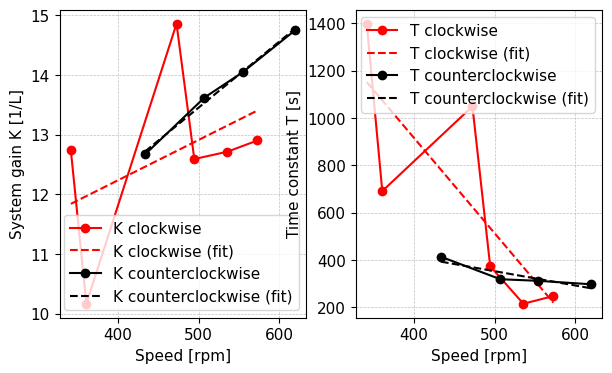

In [14]:
# maximum of rpm
RPM_cw36 = np.max(response_cw36)
RPM_cw38 = np.max(response_cw38)
RPM_cw39 = np.max(response_cw39)
RPM_cw40 = np.max(response_cw40)
RPM_cw42 = np.max(response_cw42)
RPM_cw44 = np.max(response_cw44)

RPM_ccw36 = np.max(response_ccw36)
RPM_ccw38 = np.max(response_ccw38)
RPM_ccw40 = np.max(response_ccw40)
RPM_ccw42 = np.max(response_ccw42)

RPM = [RPM_cw36, RPM_cw38, RPM_cw39, RPM_cw40, RPM_cw42, RPM_cw44]
RPMc = [RPM_ccw36, RPM_ccw38, RPM_ccw40, RPM_ccw42]

coef_K_cw = np.polyfit([*RPM], [*K_cw], 1)
poly1d_fn_K_cw = np.poly1d(coef_K_cw)
coef_T_cw = np.polyfit([*RPM], [*T_cw], 1)
poly1d_fn_T_cw = np.poly1d(coef_T_cw)

coef_K_ccw = np.polyfit([*RPMc], [*K_ccw], 1)
poly1d_fn_K_ccw = np.poly1d(coef_K_ccw)
coef_T_ccw = np.polyfit([*RPMc], [*T_ccw], 1)
poly1d_fn_T_ccw = np.poly1d(coef_T_ccw)

f = [100, 200, 300, 400, 500]
K_all_cw = poly1d_fn_K_cw(f)
Ks_all_cw = poly1d_fn_K_cw(f)
T_all_cw = poly1d_fn_T_cw(f)

K_all_ccw = poly1d_fn_K_ccw(f)
Ks_all_ccw = poly1d_fn_K_ccw(f)
T_all_ccw = poly1d_fn_T_ccw(f)

print("The modelled K and T values are:\n")
print("rpm: K, T (clockwise)")
for i in range(len(f)):
    print(f"{f[i]:3d}: {K_all_cw[i]:.2f}, {T_all_cw[i]:.2f}")
print("rpm: K, T (counterclockwise)")
for i in range(len(f)):
    print(f"{f[i]:3d}: {K_all_ccw[i]:.2f}, {T_all_ccw[i]:.2f}")

# Plot of System Gains and Time Constants
fig, ax = plt.subplots(1, 2, figsize=(7, 4))

ax[0].plot(RPM, K_cw, 'ro-', label='K clockwise')
ax[0].plot(RPM, poly1d_fn_K_cw(RPM), 'r--', label='K clockwise (fit)')
ax[1].plot(RPM, T_cw, 'ro-', label='T clockwise')
ax[1].plot(RPM, poly1d_fn_T_cw(RPM), 'r--', label='T clockwise (fit)')

ax[0].plot(RPMc, K_ccw, 'ko-', label='K counterclockwise')
ax[0].plot(RPMc, poly1d_fn_K_ccw(RPMc), 'k--', label='K counterclockwise (fit)')
ax[1].plot(RPMc, T_ccw, 'ko-', label='T counterclockwise')
ax[1].plot(RPMc, poly1d_fn_T_ccw(RPMc), 'k--', label='T counterclockwise (fit)')

for i in range(2):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    ax[i].spines['bottom'].set_color('k')
    ax[i].spines['left'].set_color('k')
    ax[i].spines['right'].set_color('k')
    ax[i].spines['top'].set_color('k')
    ax[i].set_xlabel('Speed [rpm]')
ax[0].set_ylabel("System gain K [1/L]")
ax[1].set_ylabel("Time constant T [s]")
ax[0].legend(loc=4)
ax[1].legend(loc=1)

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig) # call this for legend fix
# tpl.save('tikz/steptest/KT.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

The modelled Ks and T values are:

rpm: Ks, T (clockwise)
300: 402.26, 1321.37
400: 465.26, 917.88
500: 528.27, 514.39
700: 654.27, -292.58
rpm: Ks, T (counterclockwise)
300: 336.90, 474.66
400: 425.20, 414.08
500: 513.51, 353.51
700: 690.13, 232.36


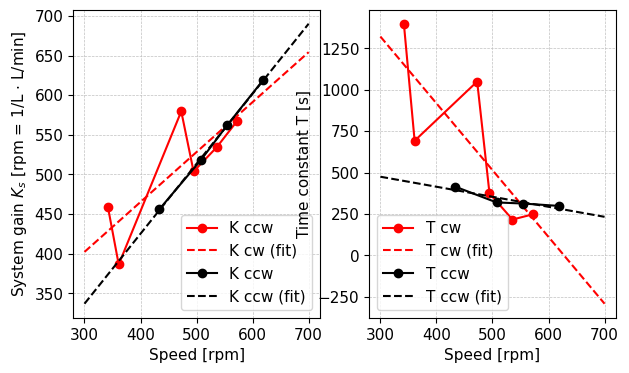

In [15]:
# maximum of rpm
RPM_cw36 = np.max(response_cw36)
RPM_cw38 = np.max(response_cw38)
RPM_cw39 = np.max(response_cw39)
RPM_cw40 = np.max(response_cw40)
RPM_cw42 = np.max(response_cw42)
RPM_cw44 = np.max(response_cw44)

RPM_ccw36 = np.max(response_ccw36)
RPM_ccw38 = np.max(response_ccw38)
RPM_ccw40 = np.max(response_ccw40)
RPM_ccw42 = np.max(response_ccw42)

RPM = [RPM_cw36, RPM_cw38, RPM_cw39, RPM_cw40, RPM_cw42, RPM_cw44]
RPMc = [RPM_ccw36, RPM_ccw38, RPM_ccw40, RPM_ccw42]

coef_Ks_cw = np.polyfit([*RPM], [*Ks_cw], 1)
poly1d_fn_Ks_cw = np.poly1d(coef_Ks_cw)
coef_T_cw = np.polyfit([*RPM], [*T_cw], 1)
poly1d_fn_T_cw = np.poly1d(coef_T_cw)

coef_Ks_ccw = np.polyfit([*RPMc], [*Ks_ccw], 1)
poly1d_fn_Ks_ccw = np.poly1d(coef_Ks_ccw)
coef_T_ccw = np.polyfit([*RPMc], [*T_ccw], 1)
poly1d_fn_T_ccw = np.poly1d(coef_T_ccw)

f = [300, 400, 500, 700]
Ks_all_cw = poly1d_fn_Ks_cw(f)
T_all_cw = poly1d_fn_T_cw(f)

Ks_all_ccw = poly1d_fn_Ks_ccw(f)
T_all_ccw = poly1d_fn_T_ccw(f)

print("The modelled Ks and T values are:\n")
print("rpm: Ks, T (clockwise)")
for i in range(len(f)):
    print(f"{f[i]:3d}: {Ks_all_cw[i]:.2f}, {T_all_cw[i]:.2f}")
print("rpm: Ks, T (counterclockwise)")
for i in range(len(f)):
    print(f"{f[i]:3d}: {Ks_all_ccw[i]:.2f}, {T_all_ccw[i]:.2f}")

# Plot of System Gains and Time Constants
fig, ax = plt.subplots(1, 2, figsize=(7, 4))

ax[0].plot(RPM, Ks_cw, 'ro-', label='K ccw')
ax[0].plot(f, poly1d_fn_Ks_cw(f), 'r--', label='K cw (fit)')
ax[1].plot(RPM, T_cw, 'ro-', label='T cw')
ax[1].plot(f, poly1d_fn_T_cw(f), 'r--', label='T cw (fit)')

ax[0].plot(RPMc, Ks_ccw, 'ko-', label='K ccw')
ax[0].plot(f, poly1d_fn_Ks_ccw(f), 'k--', label='K ccw (fit)')
ax[1].plot(RPMc, T_ccw, 'ko-', label='T ccw')
ax[1].plot(f, poly1d_fn_T_ccw(f), 'k--', label='T ccw (fit)')

for i in range(2):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    ax[i].spines['bottom'].set_color('k')
    ax[i].spines['left'].set_color('k')
    ax[i].spines['right'].set_color('k')
    ax[i].spines['top'].set_color('k')
    ax[i].set_xlabel('Speed [rpm]')
ax[0].set_ylabel(r"System gain $K_s$ [rpm = 1/L $\cdot$ L/min]")
ax[1].set_ylabel("Time constant T [s]")
ax[0].legend(loc=4)
ax[1].legend(loc="lower left")

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig) # call this for legend fix
# tpl.save('tikz/steptest/KsT.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

Dependencies

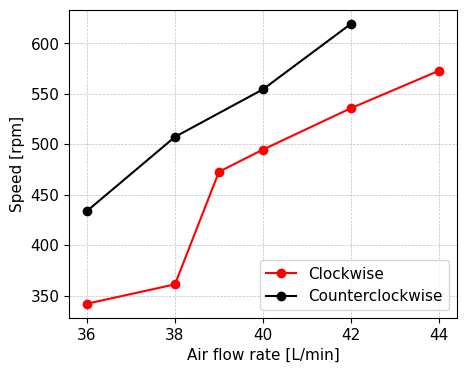

In [16]:
# Plot rpm over flow
flow = [36, 38, 39, 40, 42, 44]
flowc = [36, 38, 40, 42]

fig, ax = plt.subplots(1, 1, figsize=(5, 4))

ax.plot(flow, RPM, 'ro-', label='Clockwise')
ax.plot(flowc, RPMc, 'ko-', label='Counterclockwise')

ax.grid(color='silver', linestyle='--', linewidth=0.5)
ax.spines['bottom'].set_color('k')
ax.spines['left'].set_color('k')
ax.spines['right'].set_color('k')
ax.spines['top'].set_color('k')
ax.legend(loc=4)
ax.set_xlabel('Air flow rate [L/min]')
ax.set_ylabel("Speed [rpm]")

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig) # call this for legend fix
# tpl.save('tikz/steptest/rpm_flow.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

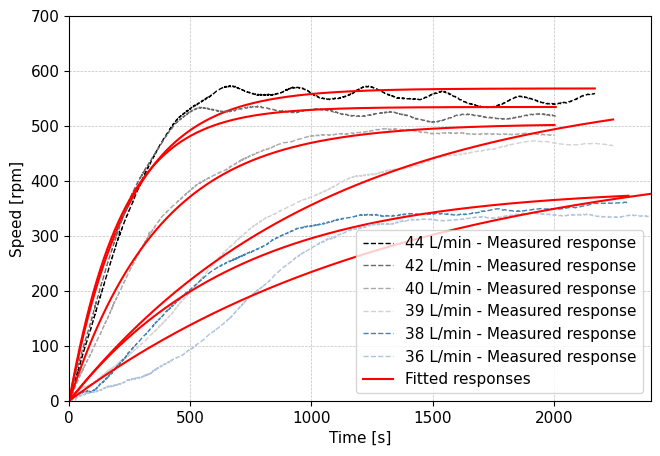

In [17]:
# Plot of Stepresponses CLOCKWISE
fig2, ax2 = plt.subplots(1, 1, figsize=(7.5, 5))

ax2.plot(time_cw44, response_cw44, 'black', linestyle='--', linewidth=1, label='44 L/min - Measured response')
ax2.plot(time_cw44, response_ident_cw44*44, 'r-')
ax2.plot(time_cw42, response_cw42, 'dimgray', linestyle='--', linewidth=1, label='42 L/min - Measured response')
ax2.plot(time_cw42, response_ident_cw42*42, 'r-')
ax2.plot(time_cw40, response_cw40, 'darkgray', linestyle='--', linewidth=1, label='40 L/min - Measured response')
ax2.plot(time_cw40, response_ident_cw40*40, 'r-')
ax2.plot(time_cw39, response_cw39, 'lightgray', linestyle='--', linewidth=1, label='39 L/min - Measured response')
ax2.plot(time_cw39, response_ident_cw39*39, 'r-')
ax2.plot(time_cw38, response_cw38, 'steelblue', linestyle='--', linewidth=1, label='38 L/min - Measured response')
ax2.plot(time_cw38, response_ident_cw38*38, 'r-')
ax2.plot(time_cw36, response_cw36, 'lightsteelblue', linestyle='--', linewidth=1, label='36 L/min - Measured response')
ax2.plot(time_cw36, response_ident_cw36*36, 'r-', label='Fitted responses')

ax2.grid(color='silver', linestyle='--', linewidth=0.5)
ax2.spines['bottom'].set_color('k')
ax2.spines['left'].set_color('k')
ax2.spines['right'].set_color('k')
ax2.spines['top'].set_color('k')
ax2.set_xlim(0, 2600)
ax2.set_ylim(0, 600)
ax2.legend(loc=4)
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Speed [rpm]')

# # textboxes
# props = dict(boxstyle='square', facecolor='white', alpha=0.9)

# ax2.text(2500, 350, 'u=36 L/min', bbox=props)
# ax2.text(2500, 400, 'u=38 L/min', bbox=props)
# ax2.text(2500, 500, 'u=39 L/min', bbox=props)
# ax2.text(2500, 510, 'u=40 L/min', bbox=props)
# ax2.text(2500, 550, 'u=42 L/min', bbox=props)
# ax2.text(2500, 600, 'u=44 L/min', bbox=props)

ax2.set_xlim((0, 2400))
ax2.set_ylim((0, 700))

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig2) # call this for legend fix
# tpl.save('tikz/steptest/step_CW.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')
plt.savefig(f'steptest_CW.svg')

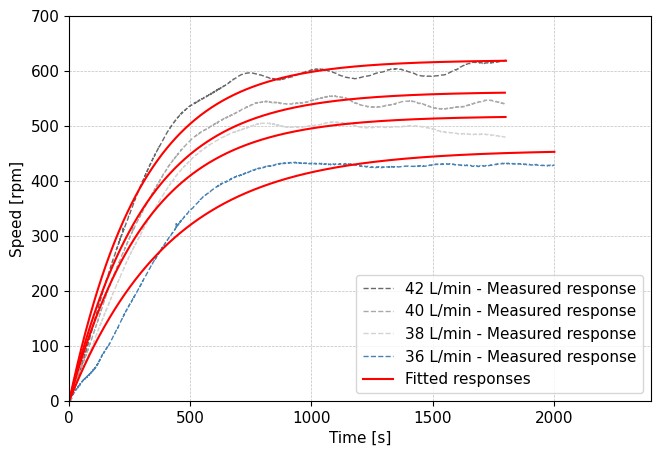

In [18]:
# Plot of Stepresponses COUNTERCLOCKWISE
fig2, ax2 = plt.subplots(1, 1, figsize=(7.5, 5))

ax2.plot(time_ccw42, response_ccw42, 'dimgray', linestyle='--', linewidth=1, label='42 L/min - Measured response')
ax2.plot(time_ccw42, response_ident_ccw42*42, 'r-')
ax2.plot(time_ccw40, response_ccw40, 'darkgray', linestyle='--', linewidth=1, label='40 L/min - Measured response')
ax2.plot(time_ccw40, response_ident_ccw40*40, 'r-')
ax2.plot(time_ccw38, response_ccw38, 'lightgray', linestyle='--', linewidth=1, label='38 L/min - Measured response')
ax2.plot(time_ccw38, response_ident_ccw38*38, 'r-')
ax2.plot(time_ccw36, response_ccw36, 'steelblue', linestyle='--', linewidth=1, label='36 L/min - Measured response')
ax2.plot(time_ccw36, response_ident_ccw36*36, 'r-', label='Fitted responses')

ax2.grid(color='silver', linestyle='--', linewidth=0.5)
ax2.spines['bottom'].set_color('k')
ax2.spines['left'].set_color('k')
ax2.spines['right'].set_color('k')
ax2.spines['top'].set_color('k')
# ax.set_xlim(-5, 200)
# ax.set_ylim(-5, 120)
ax2.legend(loc=4)
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('Speed [rpm]')
ax2.set_xlim((0, 2400))
ax2.set_ylim((0, 700))

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig2) # call this for legend fix
# tpl.save('tikz/steptest/step_CCW.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')


plt.savefig(f'steptest_CCW.svg')

In [19]:
# # CW and CCW in comparison
# fig3, ax = plt.subplots(1, 1, figsize=(12, 12))

# ax.plot(time_cw52, response_cw52, 'k', label='52 L/min measured response')
# ax.plot(time_cw52, response_ident_cw52, 'r--')
# ax.plot(time_cw48, response_cw48, 'dimgray', label='48 L/min measured response')
# ax.plot(time_cw48, response_ident_cw48, 'r--')
# ax.plot(time_cw44, response_cw44, 'darkgray', label='44 L/min measured response')
# ax.plot(time_cw44, response_ident_cw44, 'r--')
# ax.plot(time_cw40, response_cw40, 'lightgray', label='40 L/min measured response')
# ax.plot(time_cw40, response_ident_cw40, 'r--', label='CW fitted responses')

# ax.plot(time_ccw52, response_ccw52, 'k', label='CCW 52 L/min measured response')
# ax.plot(time_ccw52, response_ident_ccw52, 'b--')
# ax.plot(time_ccw48, response_ccw48, 'dimgray', label='CCW 48 L/min measured response')
# ax.plot(time_ccw48, response_ident_ccw48, 'b--')
# ax.plot(time_ccw44, response_ccw44, 'darkgray', label='CCW 44 L/min measured response')
# ax.plot(time_ccw44, response_ident_ccw44, 'b--')
# ax.plot(time_ccw40, response_ccw40, 'lightgray', label='CCW 40 L/min measured response')
# ax.plot(time_ccw40, response_ident_ccw40, 'b--', label='CCW fitted responses')

# ax.grid(color='silver', linestyle='--', linewidth=0.5)
# ax.spines['bottom'].set_color('k')
# ax.spines['left'].set_color('k')
# ax.spines['right'].set_color('k')
# ax.spines['top'].set_color('k')
# # ax.set_xlim(-5, 200)
# # ax.set_ylim(-5, 120)
# ax.legend(loc=4)
# ax.set_xlabel('time in s')
# ax.set_ylabel(r'speed in $\frac{1}{min}$')

# # save the plot to tikz file, delete plt.show()
# tikzplotlib_fix_ncols(fig3) # call this for legend fix
# # tpl.save('tikz/steptest/stepfit_amp50_CW.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

### 4. Control Parameter Estimation: Direkte Vorgabe eines Systemverhaltens
Der geschlossene Regelkreis soll sich wie ein PT1-System verhalten. Das System hat die Übertragungsfunktion...

Wir setzen T_i = T für ähnliches dynamisches Verhalten von Regler und Strecke.

Zeitkonstante des Regelkreises T_sys geben wir vor auf eine gewünschte Dauer.

Daraus ergibt sich für K_P=....

In [20]:
def pi_parameters(K, T, Tsys):
    K = K/60 # min to seconds
    Kp = T / (K*Tsys)
    Ti = T
    Ki = Kp / Ti
    return Kp, Ti, Ki

Tsys = 20 # Desired system behavior

Kp_cw36, Ti_cw36, Ki_cw36 = pi_parameters(K_s_cw36, T_est_cw36, Tsys)
Kp_cw38, Ti_cw38, Ki_cw38 = pi_parameters(K_s_cw38, T_est_cw38, Tsys)
Kp_cw39, Ti_cw39, Ki_cw39 = pi_parameters(K_s_cw39, T_est_cw39, Tsys)
Kp_cw40, Ti_cw40, Ki_cw40 = pi_parameters(K_s_cw40, T_est_cw40, Tsys)
Kp_cw42, Ti_cw42, Ki_cw42 = pi_parameters(K_s_cw42, T_est_cw42, Tsys)
Kp_cw44, Ti_cw44, Ki_cw44 = pi_parameters(K_s_cw44, T_est_cw44, Tsys)

Kp_ccw36, Ti_ccw36, Ki_ccw36 = pi_parameters(K_s_ccw36, T_est_ccw36, Tsys)
Kp_ccw38, Ti_ccw38, Ki_ccw38 = pi_parameters(K_s_ccw38, T_est_ccw38, Tsys)
Kp_ccw40, Ti_ccw40, Ki_ccw40 = pi_parameters(K_s_ccw40, T_est_ccw40, Tsys)
Kp_ccw42, Ti_ccw42, Ki_ccw42 = pi_parameters(K_s_ccw42, T_est_ccw42, Tsys)

# print("**************************************************")
# print(f"Time Constant (T):          {T_est_cw40} [s]")
# print(f"System Gain (K_PS):         {K_est_cw40/60} [1/s]")
# print("**************************************************")
# print(f"Proportional Gain (Kp):     {Kp_cw40} [s]")
# print(f"Integral Time (Ti):         {Ti_cw40} [s]")
# print(f"Integral Gain (Ki):         {Ki_cw40} [1/s]")

print(f"        K_p       K_i       T_i")
print(f"CW36    {Kp_cw36:.2f}     {Ki_cw36:.3f}      {Ti_cw36:.2f}")
print(f"CW38    {Kp_cw38:.2f}     {Ki_cw38:.3f}      {Ti_cw38:.2f}")
print(f"CW39    {Kp_cw39:.2f}     {Ki_cw39:.3f}      {Ti_cw39:.2f}")
print(f"CW40    {Kp_cw40:.2f}     {Ki_cw40:.3f}      {Ti_cw40:.2f}")
print(f"CW42    {Kp_cw42:.2f}     {Ki_cw42:.3f}      {Ti_cw42:.2f}")
print(f"CW44    {Kp_cw44:.2f}     {Ki_cw44:.3f}      {Ti_cw44:.2f}")

print("\n")
print(f"CCW36    {Kp_ccw36:.2f}     {Ki_ccw36:.3f}      {Ti_ccw36:.2f}")
print(f"CCW38    {Kp_ccw38:.2f}     {Ki_ccw38:.3f}      {Ti_ccw38:.2f}")
print(f"CCW40    {Kp_ccw40:.2f}     {Ki_ccw40:.3f}      {Ti_ccw40:.2f}")
print(f"CCW42    {Kp_ccw42:.2f}     {Ki_ccw42:.3f}      {Ti_ccw42:.2f}")

Kp_cw = np.array([Kp_cw36,Kp_cw38,Kp_cw39,Kp_cw40,Kp_cw42,Kp_cw44])
Ki_cw = np.array([Ki_cw36,Ki_cw38,Ki_cw39,Ki_cw40,Ki_cw42,Ki_cw44])

Kp_ccw = np.array([Kp_cw36,Kp_cw38,Kp_cw40,Kp_cw42])
Ki_ccw = np.array([Ki_cw36,Ki_cw38,Ki_cw40,Ki_cw42])

# print(Kp_cw, Kp_ccw)
# print(Ki_cw, Ki_ccw)

        K_p       K_i       T_i
CW36    9.15     0.007      1398.89
CW38    5.37     0.008      691.82
CW39    5.43     0.005      1049.70
CW40    2.23     0.006      374.11
CW42    1.21     0.006      215.95
CW44    1.31     0.005      248.20


CCW36    2.73     0.007      414.39
CCW38    1.85     0.006      319.43
CCW40    1.67     0.005      312.67
CCW42    1.44     0.005      298.12


In [21]:
# Linear regression m*x+b
x = [30, 100, 200, 300, 400, 500, 600, 700, 800]
# print(x)
# Kp
coef_Kp_cw = np.polyfit(K_cw, Kp_cw, 1)
poly1d_fn_Kp_cw = np.poly1d(coef_Kp_cw)
# print(poly1d_fn_Kp_cw)
coef_Kp_ccw = np.polyfit(K_ccw, Kp_ccw, 1)
poly1d_fn_Kp_ccw = np.poly1d(coef_Kp_ccw)
# print(poly1d_fn_Kp_ccw)

poly1d_fn_Kp = (poly1d_fn_Kp_cw + poly1d_fn_Kp_ccw)/2
# print(poly1d_fn_Kp) # median line
# print(poly1d_fn_Kp(x))

# Ki
# print([K_cw, K_ccw])
# print([*K_cw, *K_ccw])
K_new = [*K_cw, *K_ccw]
K_new = K_new[1:]
# print(K_new)
Ki_new = [*Ki_cw, *Ki_ccw]
Ki_new = Ki_new[1:]
# print(Ki_new)
coef_Ki = np.polyfit(K_new, Ki_new, 1)
poly1d_fn_Ki = np.poly1d(coef_Ki)
# print(poly1d_fn_Ki)


# all values
Kp_all = poly1d_fn_Kp(x)
Ki_all = poly1d_fn_Ki(x)
Ti_all = Kp_all / Ki_all
print(Kp_all, Ki_all)
print("We use the following Kp and Ki values:")
print("rpm: Kp, Ki, Ti")
for i in range(len(x)):
    print(f"{x[i]:3d}: {Kp_all[i]:.2f}, {Ki_all[i]:.2f}, {Ti_all[i]:.2f}")

[  -28.65101583  -170.69424221  -373.61313703  -576.53203186
  -779.45092669  -982.36982151 -1185.28871634 -1388.20761117
 -1591.126506  ] [-0.00044928 -0.02801181 -0.06738687 -0.10676192 -0.14613697 -0.18551202
 -0.22488707 -0.26426212 -0.30363717]
We use the following Kp and Ki values:
rpm: Kp, Ki, Ti
 30: -28.65, -0.00, 63771.12
100: -170.69, -0.03, 6093.65
200: -373.61, -0.07, 5544.30
300: -576.53, -0.11, 5400.17
400: -779.45, -0.15, 5333.70
500: -982.37, -0.19, 5295.45
600: -1185.29, -0.22, 5270.60
700: -1388.21, -0.26, 5253.15
800: -1591.13, -0.30, 5240.22


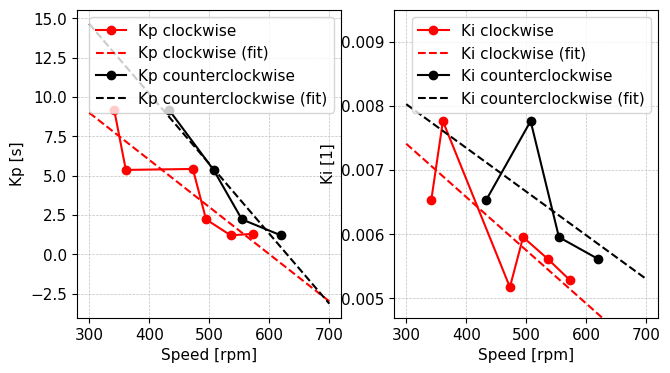

In [22]:
# Plot of PI Control Parameters in comparison
s = np.array([300, 400, 500, 600, 700])

coef_Kp_cw = np.polyfit(RPM, Kp_cw, 1)
poly1d_fn_Kp_cw = np.poly1d(coef_Kp_cw)
coef_Ki_cw = np.polyfit(RPM, Ki_cw, 1)
poly1d_fn_Ki_cw = np.poly1d(coef_Ki_cw)

coef_Kp_ccw = np.polyfit(RPMc, Kp_ccw, 1)
poly1d_fn_Kp_ccw = np.poly1d(coef_Kp_ccw)
coef_Ki_ccw = np.polyfit(RPMc, Ki_ccw, 1)
poly1d_fn_Ki_ccw = np.poly1d(coef_Ki_ccw)

fig, ax = plt.subplots(1, 2, figsize=(7.5, 4))

ax[0].plot(RPM, Kp_cw, 'ro-', label='Kp clockwise')
ax[0].plot(s, poly1d_fn_Kp_cw(s), '--r', label=f"Kp clockwise (fit)")
ax[1].plot(RPM, Ki_cw, 'ro-', label='Ki clockwise')
ax[1].plot(s, poly1d_fn_Ki_cw(s), '--r', label=f"Ki clockwise (fit)")

ax[0].plot(RPMc, Kp_ccw, 'ko-', label='Kp counterclockwise')
ax[0].plot(s, poly1d_fn_Kp_ccw(s), '--k', label=f"Kp counterclockwise (fit)")
ax[1].plot(RPMc, Ki_ccw, 'ko-', label='Ki counterclockwise')
ax[1].plot(s, poly1d_fn_Ki_ccw(s), '--k', label=f"Ki counterclockwise (fit)")

for i in range(2):
    ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
    ax[i].spines['bottom'].set_color('k')
    ax[i].spines['left'].set_color('k')
    ax[i].spines['right'].set_color('k')
    ax[i].spines['top'].set_color('k')
    ax[i].legend(loc=1)
    ax[i].set_xlabel('Speed [rpm]')
ax[0].set_ylabel("Kp [s]")
ax[1].set_ylabel("Ki [1]")
ax[1].set_ylim(0.0047, 0.0095)

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig) # call this for legend fix
# tpl.save('tikz/steptest/KpKi.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

In [23]:
s = np.array([100, 200, 300, 400, 500])
m_s = (s/60) * (2 * np.pi * 0.0647)
print(f"Speed in rpm: {s}")
print(f"Speed in m/s: {m_s}")
print(f"Kp clockwise: {poly1d_fn_Kp_cw(s)}")
print(f"Ki clockwise: {poly1d_fn_Ki_cw(s)}")
print(f"Kp counterclockwise: {poly1d_fn_Kp_ccw(s)}")
print(f"Ki counterclockwise: {poly1d_fn_Ki_ccw(s)}")

# # Plot of PI Control Parameters
# fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# ax[0].plot(s, poly1d_fn_Kp_cw(s), 'ro--', label=f"Fitted Kp clockwise")
# ax[1].plot(s, poly1d_fn_Ki_cw(s), 'ro--', label=f"Fitted Ki clockwise")

# ax[0].plot(s, poly1d_fn_Kp_ccw(s), 'ko--', label=f"Fitted Kp counterclockwise")
# ax[1].plot(s, poly1d_fn_Ki_ccw(s), 'ko--', label=f"Fitted Ki counterclockwise")

# for i in range(2):
#     ax[i].grid(color='silver', linestyle='--', linewidth=0.5)
#     ax[i].spines['bottom'].set_color('k')
#     ax[i].spines['left'].set_color('k')
#     ax[i].spines['right'].set_color('k')
#     ax[i].spines['top'].set_color('k')
#     ax[i].legend(loc=1)
#     ax[i].set_xlabel(r'Speed in $\frac{1}{min}$')
# ax[0].set_ylabel("Kp [s]")
# ax[1].set_ylabel("Ki [1]")

# save the plot to tikz file, delete plt.show()
# tikzplotlib_fix_ncols(fig) # call this for legend fix
# tpl.save('tikz/steptest/stepfit_amp50_CW.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

Speed in rpm: [100 200 300 400 500]
Speed in m/s: [0.67753682 1.35507363 2.03261045 2.71014726 3.38768408]
Kp clockwise: [15.00268709 12.0053272   9.00796731  6.01060742  3.01324752]
Ki clockwise: [0.00907321 0.00824241 0.00741161 0.00658081 0.00575001]
Kp counterclockwise: [23.55905987 19.11067321 14.66228655 10.21389989  5.76551323]
Ki counterclockwise: [0.00939151 0.00870984 0.00802817 0.00734651 0.00666484]


### 4. PID Tuning with Python
(https://simonebertonilab.com/pid-tuning-the-power-of-python/)

Finding the optimal PID parameters by turning the tuning problem in an optimization problem. Goal then is to minimize a specific cost function.

$J=\sum_{i=1}^{N-1}[W_e\cdot (r_i - y_i)^2 + W_u \cdot u_{sat_i}^2]$

Regelabweichung: $W_e\cdot (r_i - y_i)^2$

Steuergrößenaufwand: $W_u \cdot u_{sat_i}^2$

We and Wu are the weighting coefficients. Their choice determines the compromise between minimizing the error and minimizing the control effort:

W_e > W_u: Minimizing the error takes precedence over minimizing control effort.

W_e < W_u: Minimizing control effort is more important than minimizing the error.

In [24]:
print(K_est_cw40/60)
print(T_est_cw40)

0.209892749608906
374.1081861316177


Optimierte Parameter: Kp = 3531.521338444687, Ki = 1.5


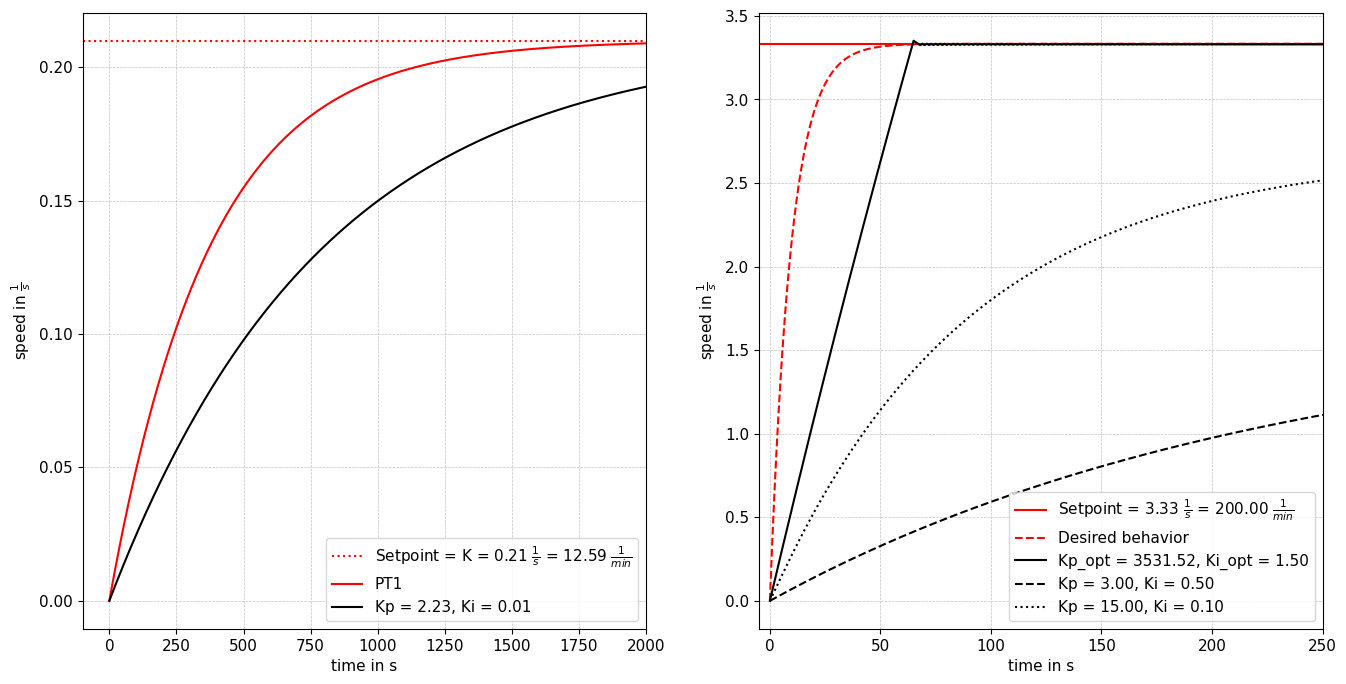

In [25]:
# PT1 System
def PT1(t, K, T, dt):
    for i in range(1, len(t)):
        dydt = (-y[i-1] + K) / T
        y[i] = y[i-1] + dydt * dt
    return y

def PT1x(t, Kx, Tx, dt):
    for i in range(1, len(t)):
        dydt = (-yx[i-1] + Kx) / Tx
        yx[i] = yx[i-1] + dydt * dt
    return yx

# Simulation des PT1-Systems mit PI-Regelung (geschlossener Regelkreis)
def PT1PI(t, Kp, Ki, setpoint, K, T, dt):
    for k in range(1, len(t)):
        # error
        e[k] = setpoint - y2[k-1]

        # integral term
        I[k] = I[k-1] + e[k] * dt
        ITerm[k] = Ki * I[k]

        # anti windup
        if windup != 0:
            if ITerm[k] > windup:
                ITerm[k] = windup
            elif ITerm[k] < -windup:
                ITerm[k] = -windup

        # output
        u[k] = Kp * e[k] + ITerm[k]
        u_clipped[k] = np.clip(u[k], 0, 100) # Begrenzung output
        u_sat[k] = u_clipped[k]  # gesättigter Reglerausgang

        # PT1 mit output vom PI Regler
        dydt2 = (-y2[k-1] + K * u_clipped[k]) / T
        y2[k] = y2[k-1] + dydt2 * dt
    return y2, u_sat

# Kostenfunktion definieren
def cost_function(params, t, setpoint, K, T, dt, target_response):
    Kp, Ki = params
    y2, u_sat = PT1PI(t, Kp, Ki, setpoint, K, T, dt)
    # Fehler berechnen
    error = (target_response - y2) ** 2
    # Kosten berechnen
    cost = np.sum(W_e * error + W_u * np.square(u_sat))
    return cost

def find_pi_parameters(t, setpoint, K, T, dt, target_response):
    initial_guess = [3.0, 1.5]  # Startwerte
    bounds = [(0, None), (0, None)]  # Setzt sowohl für Kp als auch für Ki untere Schranken auf 0
    result = minimize(cost_function, initial_guess, args=(t, setpoint, K, T, dt, target_response), bounds=bounds)
    return result.x # Array mit den optimalen Werten für die Parameter, die optimiert wurden. 


setpoint = 200/60

# PT1-System-Parameter
K = K_est_cw40/60  # Verstärkung des PT1-Systems in 1/min
T = T_est_cw40  # Zeitkonstante des PT1-Systems
dt = 1.0  # Zeitdiskretisierung
end_time = 2500  # Endzeit der Simulation

# Diskrete Zeitvektor
t = np.arange(0, end_time, dt)

# Initialisierung der Antwort und der Reglergrößen
y = np.zeros_like(t)
yx = np.zeros_like(t)
y2 = np.zeros_like(t)
u = np.zeros_like(t)
u_clipped = np.zeros_like(t)
e = np.zeros_like(t)
I = np.zeros_like(t)
ITerm = np.zeros_like(t)
u_sat = np.zeros(len(t))

# Threshold Anti windup
windup = 3

# PI-Regler-Parameter
Kp = Kp_cw40
Ti = Ti_cw40
Ki = Ki_cw40

# Zielantwort definieren (z.B. Sprungantwort des PT1 ohne Regler)
K2 = setpoint
T2 = 10
target_response = PT1x(t, K2, T2, dt)
pt1_response = PT1(t, K, T, dt)

# Gewichtungsfaktoren
W_e = 5.0  # Gewichtung des Fehleranteils
W_u = 0.0  # Gewichtung des Steuergrößenaufwands

Kp_opt, Ki_opt = find_pi_parameters(t, setpoint, K, T, dt, target_response)
print(f"Optimierte Parameter: Kp = {Kp_opt}, Ki = {Ki_opt}")

Kp_opt2 = 3
Ki_opt2 = 0.5

Kp4 = 15
Ki4 = 0.1
# Plot der Systemantworten
fig3, ax3 = plt.subplots(1, 2, figsize=(16, 8))

# ax3[0].axhline(K, color='r', linestyle=':', label='K')
ax3[0].axhline(K, color='r', linestyle=':', label=f"Setpoint = K = {K:.2f} " r'$\frac{1}{s}$' f" = {60*K:.2f} " r'$\frac{1}{min}$')
ax3[0].plot(t, pt1_response, 'r', label='PT1')
# ax3[0].plot(t, target_response, 'k:', label='Desired behavior')
ax3[0].plot(t, PT1PI(t, Kp, Ki, K, K, T, dt)[0], 'k', label=f"Kp = {Kp:.2f}, Ki = {Ki:.2f}")

ax3[1].axhline(setpoint, color='r', linestyle='-', label=f"Setpoint = {setpoint:.2f} " r'$\frac{1}{s}$' f" = {60*setpoint:.2f} " r'$\frac{1}{min}$')
ax3[1].plot(t, target_response, 'r--', label='Desired behavior')
ax3[1].plot(t, PT1PI(t, Kp_opt, Ki_opt, setpoint, K, T, dt)[0], 'k', label=f"Kp_opt = {Kp_opt:.2f}, Ki_opt = {Ki_opt:.2f}")
ax3[1].plot(t, PT1PI(t, Kp_opt2, Ki_opt2, setpoint, K, T, dt)[0], 'k--', label=f"Kp = {Kp_opt2:.2f}, Ki = {Ki_opt2:.2f}")
ax3[1].plot(t, PT1PI(t, Kp4, Ki4, setpoint, K, T, dt)[0], 'k:', label=f"Kp = {Kp4:.2f}, Ki = {Ki4:.2f}")

for i in range(2):
    ax3[i].grid(color='silver', linestyle='--', linewidth=0.5)
    ax3[i].spines['bottom'].set_color('k')
    ax3[i].spines['left'].set_color('k')
    ax3[i].spines['right'].set_color('k')
    ax3[i].spines['top'].set_color('k')
    ax3[i].legend(loc=4)
    ax3[i].set_xlabel('time in s')
    ax3[i].set_ylabel(r'speed in $\frac{1}{s}$')
ax3[0].set_xlim(-100, 2000)
ax3[1].set_xlim(-5, 250)

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig3) # call this for legend fix
# tpl.save('tikz/steptest/pt1pi_amp50_CW.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

### 5. Simulation der Antworten
Ein geschlossener Regelkreis mit einem PT1-System (Strecke) und einem PI-Regler (Proportional-Integral-Regler)

**Differenzengleichung des PT1-Systems:**

$y[k+1] = y[k] + \frac{(-y[k] + K \cdot u[k]) \cdot \Delta t}{T}$

wobei $y[k]$ der Ausgang des PT1-Systems und $u[k]$ der Eingang ist.

**Differenzengleichung des PI-Reglers:**

$e[k] = \text{setpoint} - y[k]$

$I[k+1] = I[k] + e[k] \cdot \Delta t$

$u[k] = K_p \cdot e[k] + K_i \cdot I[k]$

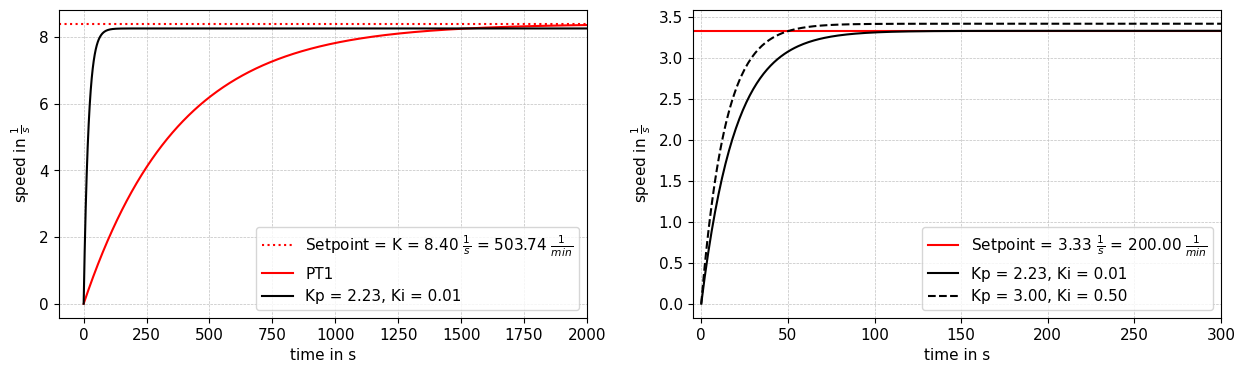

In [26]:
# PT1-System-Parameter
K = 40*K_est_cw40/60  # Verstärkung des PT1-Systems in 1/s
T = T_est_cw40  # Zeitkonstante des PT1-Systems
dt = 1.0  # Zeitdiskretisierung
end_time = 2500  # Endzeit der Simulation

# PI-Regler-Parameter
Kp = Kp_cw40
Ti = Ti_cw40
Ki = Ki_cw40
setpoint = K # 200/60  # Sollwert in 1/s

# PI Parameter 2 and 3
Kp2 = 3
Ki2 = 0.5
setpoint2 = 200/60
Kp3 = Kp_opt
Ki3 = Ki_opt

# Diskrete Zeitvektor
t = np.arange(0, end_time, dt)

# Initialisierung der Antwort und der Reglergrößen
y = np.zeros_like(t)
y2 = np.zeros_like(t)
u = np.zeros_like(t)
u_clipped = np.zeros_like(t)
e = np.zeros_like(t)
I = np.zeros_like(t)
ITerm = np.zeros_like(t)
windup = 40/60

# Simulation des PT1-Systems
def PT1(t):
    for i in range(1, len(t)):
        dydt = (-y[i-1] + K) / T
        y[i] = y[i-1] + dydt * dt
    return y

# Simulation des PT1-Systems mit PI-Regelung (geschlossener Regelkreis)
def PT1PI(t, Kp, Ki, setpoint):
    for k in range(1, len(t)):
        # error
        e[k] = setpoint - y2[k-1]

        # integral term
        I[k] = I[k-1] + e[k] * dt
        ITerm[k] = Ki * I[k]

        # anti windup
        if windup != 0:
            if ITerm[k] > windup:
                ITerm[k] = windup
            elif ITerm[k] < -windup:
                ITerm[k] = -windup

        # output
        u[k] = Kp * e[k] + ITerm[k]
        u_clipped[k] = np.clip(u[k], 0, 100)
        dydt2 = (-y2[k-1] + K * u_clipped[k]) / T
        y2[k] = y2[k-1] + dydt2 * dt
    return y2


# Plot der Systemantworten
fig3, ax3 = plt.subplots(1, 2, figsize=(15, 4))

# ax3[0].axhline(K, color='r', linestyle=':', label='K')
ax3[0].axhline(setpoint, color='r', linestyle=':', label=f"Setpoint = K = {K:.2f} " r'$\frac{1}{s}$' f" = {60*K:.2f} " r'$\frac{1}{min}$')
ax3[0].plot(t, PT1(t), 'r', label='PT1')
ax3[0].plot(t, PT1PI(t, Kp, Ki, setpoint), 'k', label=f"Kp = {Kp:.2f}, Ki = {Ki:.2f}")

ax3[1].axhline(setpoint2, color='r', linestyle='-', label=f"Setpoint = {setpoint2:.2f} " r'$\frac{1}{s}$' f" = {60*setpoint2:.2f} " r'$\frac{1}{min}$')
ax3[1].plot(t, PT1PI(t, Kp, Ki, setpoint2), 'k', label=f"Kp = {Kp:.2f}, Ki = {Ki:.2f}")
ax3[1].plot(t, PT1PI(t, Kp2, Ki2, setpoint2), 'k--', label=f"Kp = {Kp2:.2f}, Ki = {Ki2:.2f}")
# ax3[1].plot(t, PT1PI(t, Kp3, Ki3, setpoint2), 'k', linestyle=':', label=f"Kp = {Kp3:.2f}, Ki = {Ki3:.2f}")

for i in range(2):
    ax3[i].grid(color='silver', linestyle='--', linewidth=0.5)
    ax3[i].spines['bottom'].set_color('k')
    ax3[i].spines['left'].set_color('k')
    ax3[i].spines['right'].set_color('k')
    ax3[i].spines['top'].set_color('k')
    ax3[i].legend(loc=4)
    ax3[i].set_xlabel('time in s')
    ax3[i].set_ylabel(r'speed in $\frac{1}{s}$')
ax3[0].set_xlim(-100, 2000)
ax3[1].set_xlim(-5, 300)

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig3) # call this for legend fix
# tpl.save('tikz/steptest/pt1pi_amp50_CW.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

### 6. Stability

#### 6.1 Closed loop Stability in the frequency domain (Bode)
"The frequency domain allows us to find the stability of closed loop systems using only open loop transfer functions and simple operations."
https://dynamics-and-control.readthedocs.io/en/latest/2_Control/4_Frequency_domain_analysis_of_control_systems/Frequency%20domain%20stability.html

"The magnitude and angle of the frequency response is shown as a function of frequency." 
https://dynamics-and-control.readthedocs.io/en/latest/1_Dynamics/8_Frequency_domain/Frequency%20response%20plots.html#Bode

PT1 System Transfer Function:
$G_{PT1}(s)=\frac{K}{T\cdot s+1}$

PI Controller Transfer Function:
$G_{PI}(s)=K_P(1+\frac{1}{T_I\cdot s})=K_P+\frac{K_P}{T_I\cdot s}=K_P+\frac{K_I}{s}$

Open-loop Transfer Function:
$G_O(s)=G_{PT1}(s)\cdot G_{PI}(s)$

336.89579288569337 474.65597714280176
G_cl = <TransferFunction>: sys[15]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

         1.727e+07 s^3 + 2.915e+06 s^2 + 6064 s
  -----------------------------------------------------
  8.111e+06 s^4 + 1.73e+07 s^3 + 2.915e+06 s^2 + 6064 s
G_o = <TransferFunction>: sys[12]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  6064 s + 1011
  --------------
  2848 s^2 + 6 s


c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(
c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(


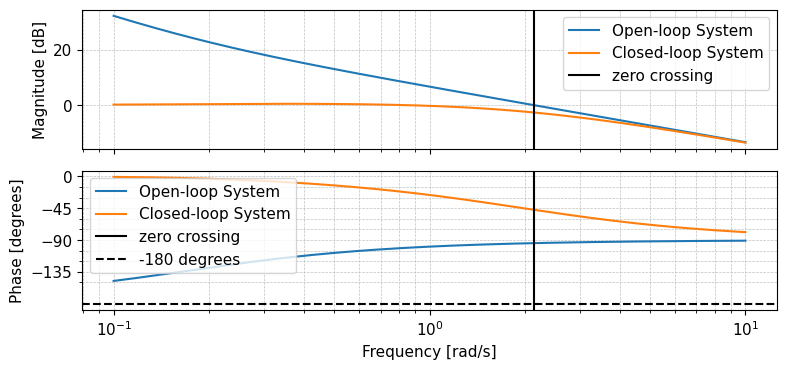

In [27]:
# Parameters
# K = K_est_cw40/60
# T = T_est_cw40
# Kp = Kp_cw40
# Ki = Ki_cw40
# Ti = Ti_cw40

# % rpm: K, T (clockwise)
# % 100: 10.20, 2128.35
# % 200: 10.88, 1724.86
# % 300: 11.56, 1321.37
# % 400: 12.24, 917.88
# % 500: 12.91, 514.39

# % rpm: K, T (counterclockwise)
# % 100: 9.02, 595.81
# % 200: 10.13, 535.23
# % 300: 11.24, 474.66
# % 400: 12.35, 414.08
# % 500: 13.46, 353.51

# rpm: Ks, T (clockwise)
# 100: 276.25, 2128.35
# 200: 339.26, 1724.86
# 300: 402.26, 1321.37
# 400: 465.26, 917.88
# 500: 528.27, 514.39
# rpm: Ks, T (counterclockwise)
# 100: 160.28, 595.81
# 200: 248.59, 535.23
# 300: 336.90, 474.66
# 400: 425.20, 414.08
# 500: 513.51, 353.51

# Parameters: Kmax-Tmax, Kmin-Tmin, Kmean-Tmean
# [0] 300 rpm 
K = Ks_all_ccw[0]
T = T_all_ccw[0]
Kp = 3
Ki = 0.5
Ti = Kp/Ki
print(K, T)

# Define PT1 system transfer function
N = np.array([T,1]) # den
G_PT1 = control.tf(K, N) # num, den
# print(f"PT1: {G_PT1}")

# Define PI controller transfer function
N_PI = np.array([Ti, 0])
G_PI = Kp * (tf(1,N_PI) + 1)

# Open-loop transfer function
G0 = G_PT1 * G_PI
# Closed-loop transfer function
Gcl = G0 / (1 + G0)
# print(f"G_closed: {Gcl}")

print(f"G_cl = {Gcl}")
print(f"G_o = {G0}")

# PLOT
fig, ax = plt.subplots(2, 1, figsize=(8, 4))

# bode(G0)
# Von 10^-4 bis 10^2 rad/s, 1000 Punkte logarithmisch verteilt
omega = np.logspace(-1, 1, 1000)
mag, phase, omega = bode(G0, omega, dB=True, deg=True)
bode(Gcl, omega, dB=True, deg=True)
zero = np.where(mag>1)[0][-1] # first point from the right that is greater than 0

# ax[0].axhline(y=0, color='k', linestyle='-')
# ax[1].axhline(y=-180, color='k', linestyle='-')
ax[0].axvline(omega[zero], color='k', linestyle='-', label='zero crossing')
ax[1].axvline(omega[zero], color='k', linestyle='-')
ax[1].axhline(y=-180, color='k', linestyle='--', label='-180')

ax[0].spines['bottom'].set_color('k')
ax[0].spines['left'].set_color('k')
ax[0].spines['right'].set_color('k')
ax[0].spines['top'].set_color('k')
# ax[0].set_xlabel('Frequency [rad/s]')
ax[0].set_ylabel('Magnitude [dB]')
ax[0].legend(['Open-loop System', 'Closed-loop System', 'zero crossing'])
ax[0].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Configure phase plot
ax[1].spines['bottom'].set_color('k')
ax[1].spines['left'].set_color('k')
ax[1].spines['right'].set_color('k')
ax[1].spines['top'].set_color('k')
ax[1].set_xlabel('Frequency [rad/s]')
ax[1].set_ylabel('Phase [degrees]')
ax[1].legend(['Open-loop System', 'Closed-loop System', 'zero crossing', '-180 degrees'], loc="upper left")
ax[1].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

ax[0].set_xscale('log')
ax[0].set_xticks([])
ax[1].set_xscale('log')

# Adjust layout and show plot
plt.suptitle("") # remove titles
plt.tight_layout()
# plt.show()
# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig) # call this for legend fix
# tpl.save('tikz/bode/bode_ccw100.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

Bode plots for the following speeds are generated:

Speed     Kp      Ki
10.17    11.59    0.01
12.59    6.67    0.01
12.67    6.51    0.01
12.72    6.42    0.01
12.74    6.38    0.01
12.90    6.04    0.01
13.62    4.58    0.01
14.05    3.72    0.01
14.75    2.29    0.01
14.86    2.07    0.01


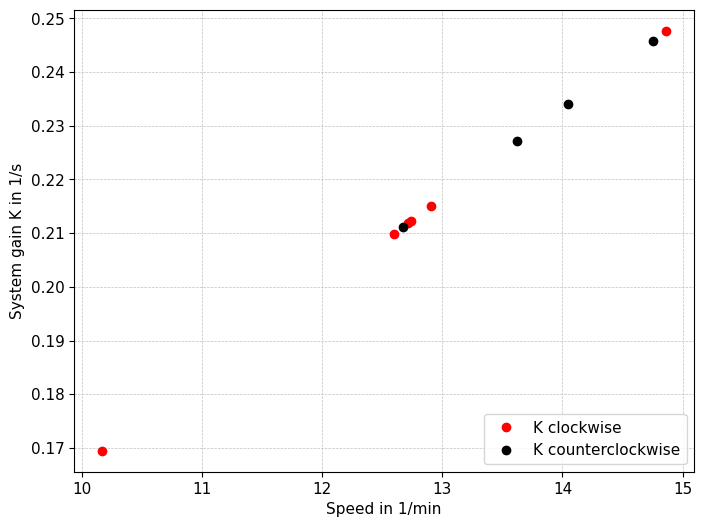

In [28]:
# print(K_est_cw40)
Speeds = np.sort(np.array([*K_cw, *K_ccw]))
print("Speed     Kp      Ki")
for i in range(len(Speeds)):
    print(f"{Speeds[i]:.2f}    {poly1d_fn_Kp(Speeds[i]):.2f}    {poly1d_fn_Ki(Speeds[i]):.2f}")

# Plot of System Gains versus Speed
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.plot(K_cw, K_cw/60, 'ro', label='K clockwise')
ax.plot(K_ccw, K_ccw/60, 'ko', label='K counterclockwise')

ax.grid(color='silver', linestyle='--', linewidth=0.5)
ax.spines['bottom'].set_color('k')
ax.spines['left'].set_color('k')
ax.spines['right'].set_color('k')
ax.spines['top'].set_color('k')
ax.legend(loc=4)
ax.set_xlabel('Speed in 1/min')
ax.set_ylabel("System gain K in 1/s")

# save the plot to tikz file, delete plt.show()
tikzplotlib_fix_ncols(fig) # call this for legend fix
# tpl.save('tikz/steptest/KT_airflow.tikz', axis_width=r'\figwidth', axis_height=r'\figheight')

Bode for flow rate of 40 L/min or speed of 160.85 1/min

c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(
c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(


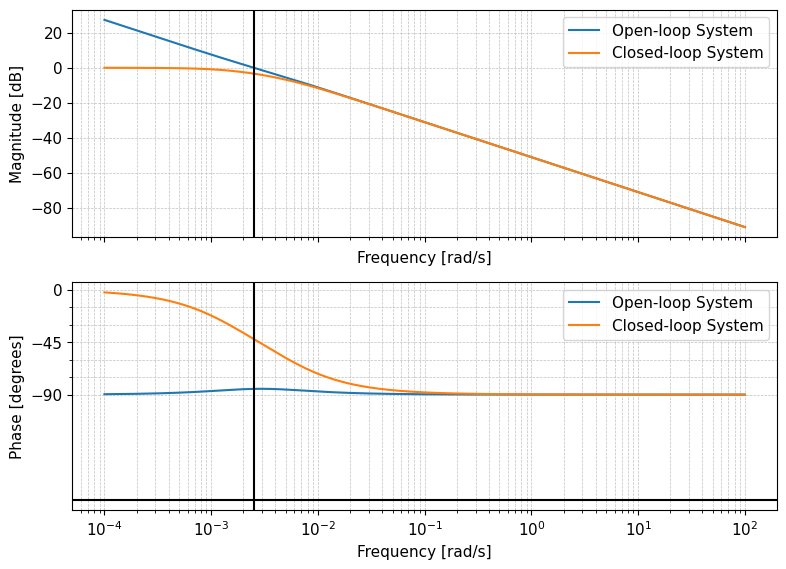

In [29]:
speed = K_est_ccw40 # 1/min
# Parameters
K = K_est_ccw40/60 #1/s
T = T_est_ccw40
Kp = round(poly1d_fn_Kp(speed),2)
Ki = round(poly1d_fn_Ki(speed),2)
Ti = Kp / Ki

# Define PT1 system transfer function
N = np.array([T,1]) # den
G_PT1 = control.tf(K, N) # num, den
# print(f"PT1: {G_PT1}")

# Define PI controller transfer function
N_PI = np.array([Ti, 0])
G_PI = Kp * (tf(1,N_PI) + 1)

# Open-loop transfer function
G0 = G_PT1 * G_PI
# Closed-loop transfer function
Gcl = G0 / (1 + G0)
# print(f"G_closed: {Gcl}")

# PLOT
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

# bode(G0)
# Von 10^-4 bis 10^2 rad/s, 1000 Punkte logarithmisch verteilt
omega = np.logspace(-4, 2, 1000)
mag, phase, omega = bode(G0, omega, dB=True, deg=True)
bode(Gcl, omega, dB=True, deg=True)
zero = np.where(mag>1)[0][-1] # first point from the right that is greater than 0

# ax[0].axhline(y=0, color='k', linestyle='-')
# ax[1].axhline(y=-180, color='k', linestyle='-')
ax[0].axvline(omega[zero], color='k', linestyle='-')
ax[1].axvline(omega[zero], color='k', linestyle='-')
ax[1].axhline(y=-180, color='k', linestyle='-')

ax[0].spines['bottom'].set_color('k')
ax[0].spines['left'].set_color('k')
ax[0].spines['right'].set_color('k')
ax[0].spines['top'].set_color('k')
ax[0].set_xlabel('Frequency [rad/s]')
ax[0].set_ylabel('Magnitude [dB]')
ax[0].legend(['Open-loop System', 'Closed-loop System'])
ax[0].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Configure phase plot
ax[1].spines['bottom'].set_color('k')
ax[1].spines['left'].set_color('k')
ax[1].spines['right'].set_color('k')
ax[1].spines['top'].set_color('k')
ax[1].set_xlabel('Frequency [rad/s]')
ax[1].set_ylabel('Phase [degrees]')
ax[1].legend(['Open-loop System', 'Closed-loop System'])
ax[1].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Adjust layout and show plot
plt.suptitle("") # remove titles
plt.tight_layout()
plt.show()

c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(
c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(


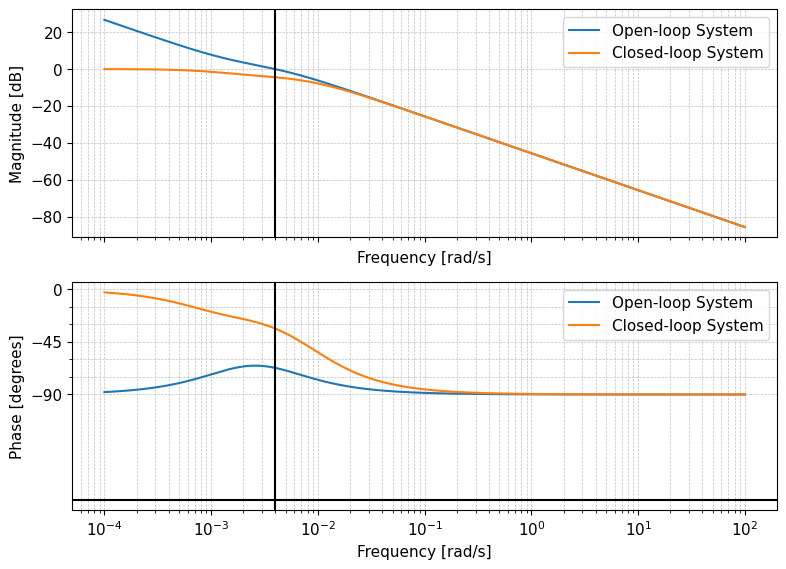

In [30]:
speed = K_est_cw44 # 1/min
# Parameters
K = K_est_cw44/60 #1/s
T = T_est_cw44
Kp = round(poly1d_fn_Kp(speed),2)
Ki = round(poly1d_fn_Ki(speed),2)
Ti = Kp / Ki

# Define PT1 system transfer function
N = np.array([T,1]) # den
G_PT1 = control.tf(K, N) # num, den
# print(f"PT1: {G_PT1}")

# Define PI controller transfer function
N_PI = np.array([Ti, 0])
G_PI = Kp * (tf(1,N_PI) + 1)

# Open-loop transfer function
G0 = G_PT1 * G_PI
# Closed-loop transfer function
Gcl = G0 / (1 + G0)
# print(f"G_closed: {Gcl}")

# PLOT
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

# bode(G0)
# Von 10^-4 bis 10^2 rad/s, 1000 Punkte logarithmisch verteilt
omega = np.logspace(-4, 2, 1000)
mag, phase, omega = bode(G0, omega, dB=True, deg=True)
bode(Gcl, omega, dB=True, deg=True)
zero = np.where(mag>1)[0][-1] # first point from the right that is greater than 0

# ax[0].axhline(y=0, color='k', linestyle='-')
# ax[1].axhline(y=-180, color='k', linestyle='-')
ax[0].axvline(omega[zero], color='k', linestyle='-')
ax[1].axvline(omega[zero], color='k', linestyle='-')
ax[1].axhline(y=-180, color='k', linestyle='-')

ax[0].spines['bottom'].set_color('k')
ax[0].spines['left'].set_color('k')
ax[0].spines['right'].set_color('k')
ax[0].spines['top'].set_color('k')
ax[0].set_xlabel('Frequency [rad/s]')
ax[0].set_ylabel('Magnitude [dB]')
ax[0].legend(['Open-loop System', 'Closed-loop System'])
ax[0].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Configure phase plot
ax[1].spines['bottom'].set_color('k')
ax[1].spines['left'].set_color('k')
ax[1].spines['right'].set_color('k')
ax[1].spines['top'].set_color('k')
ax[1].set_xlabel('Frequency [rad/s]')
ax[1].set_ylabel('Phase [degrees]')
ax[1].legend(['Open-loop System', 'Closed-loop System'])
ax[1].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Adjust layout and show plot
plt.suptitle("") # remove titles
plt.tight_layout()
plt.show()

c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(
c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(


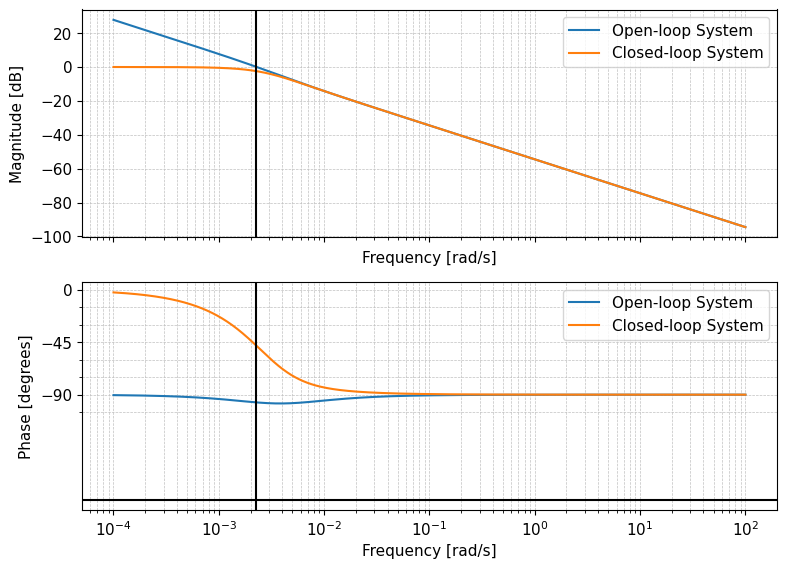

In [31]:
speed = K_est_ccw42 # 1/min
# Parameters
K = K_est_ccw42/60 #1/s
T = T_est_ccw42
Kp = round(poly1d_fn_Kp(speed),2)
Ki = round(poly1d_fn_Ki(speed),2)
Ti = Kp / Ki

# Define PT1 system transfer function
N = np.array([T,1]) # den
G_PT1 = control.tf(K, N) # num, den
# print(f"PT1: {G_PT1}")

# Define PI controller transfer function
N_PI = np.array([Ti, 0])
G_PI = Kp * (tf(1,N_PI) + 1)

# Open-loop transfer function
G0 = G_PT1 * G_PI
# Closed-loop transfer function
Gcl = G0 / (1 + G0)
# print(f"G_closed: {Gcl}")

# PLOT
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

# bode(G0)
# Von 10^-4 bis 10^2 rad/s, 1000 Punkte logarithmisch verteilt
omega = np.logspace(-4, 2, 1000)
mag, phase, omega = bode(G0, omega, dB=True, deg=True)
bode(Gcl, omega, dB=True, deg=True)
zero = np.where(mag>1)[0][-1] # first point from the right that is greater than 0

# ax[0].axhline(y=0, color='k', linestyle='-')
# ax[1].axhline(y=-180, color='k', linestyle='-')
ax[0].axvline(omega[zero], color='k', linestyle='-')
ax[1].axvline(omega[zero], color='k', linestyle='-')
ax[1].axhline(y=-180, color='k', linestyle='-')

ax[0].spines['bottom'].set_color('k')
ax[0].spines['left'].set_color('k')
ax[0].spines['right'].set_color('k')
ax[0].spines['top'].set_color('k')
ax[0].set_xlabel('Frequency [rad/s]')
ax[0].set_ylabel('Magnitude [dB]')
ax[0].legend(['Open-loop System', 'Closed-loop System'])
ax[0].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Configure phase plot
ax[1].spines['bottom'].set_color('k')
ax[1].spines['left'].set_color('k')
ax[1].spines['right'].set_color('k')
ax[1].spines['top'].set_color('k')
ax[1].set_xlabel('Frequency [rad/s]')
ax[1].set_ylabel('Phase [degrees]')
ax[1].legend(['Open-loop System', 'Closed-loop System'])
ax[1].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Adjust layout and show plot
plt.suptitle("") # remove titles
plt.tight_layout()
plt.show()

c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(
c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\freqplot.py:454: FutureWarning: bode_plot() return value of mag, phase, omega is deprecated; use frequency_response()
  warnings.warn(


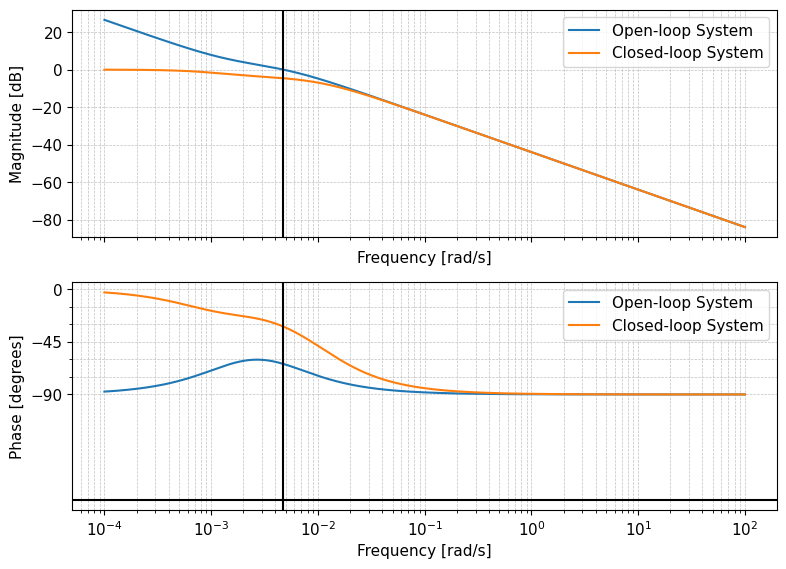

In [32]:
speed = K_est_cw42 # 1/min
# Parameters
K = K_est_cw42/60 #1/s
T = T_est_cw42
Kp = round(poly1d_fn_Kp(speed),2)
Ki = round(poly1d_fn_Ki(speed),2)
Ti = Kp / Ki

# Define PT1 system transfer function
N = np.array([T,1]) # den
G_PT1 = control.tf(K, N) # num, den
# print(f"PT1: {G_PT1}")

# Define PI controller transfer function
N_PI = np.array([Ti, 0])
G_PI = Kp * (tf(1,N_PI) + 1)

# Open-loop transfer function
G0 = G_PT1 * G_PI
# Closed-loop transfer function
Gcl = G0 / (1 + G0)
# print(f"G_closed: {Gcl}")

# PLOT
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

# bode(G0)
# Von 10^-4 bis 10^2 rad/s, 1000 Punkte logarithmisch verteilt
omega = np.logspace(-4, 2, 1000)
mag, phase, omega = bode(G0, omega, dB=True, deg=True)
bode(Gcl, omega, dB=True, deg=True)
zero = np.where(mag>1)[0][-1] # first point from the right that is greater than 0

# ax[0].axhline(y=0, color='k', linestyle='-')
# ax[1].axhline(y=-180, color='k', linestyle='-')
ax[0].axvline(omega[zero], color='k', linestyle='-')
ax[1].axvline(omega[zero], color='k', linestyle='-')
ax[1].axhline(y=-180, color='k', linestyle='-')

ax[0].spines['bottom'].set_color('k')
ax[0].spines['left'].set_color('k')
ax[0].spines['right'].set_color('k')
ax[0].spines['top'].set_color('k')
ax[0].set_xlabel('Frequency [rad/s]')
ax[0].set_ylabel('Magnitude [dB]')
ax[0].legend(['Open-loop System', 'Closed-loop System'])
ax[0].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Configure phase plot
ax[1].spines['bottom'].set_color('k')
ax[1].spines['left'].set_color('k')
ax[1].spines['right'].set_color('k')
ax[1].spines['top'].set_color('k')
ax[1].set_xlabel('Frequency [rad/s]')
ax[1].set_ylabel('Phase [degrees]')
ax[1].legend(['Open-loop System', 'Closed-loop System'])
ax[1].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Adjust layout and show plot
plt.suptitle("") # remove titles
plt.tight_layout()
plt.show()

PT1: <TransferFunction>: sys[99]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

   0.2119
  ---------
  216 s + 1
PI: <TransferFunction>: sys[100]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  4122 s + 6.42
  -------------
      642 s
Open-loop: <TransferFunction>: sys[101]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

     873.6 s + 1.361
  ---------------------
  1.386e+05 s^2 + 642 s


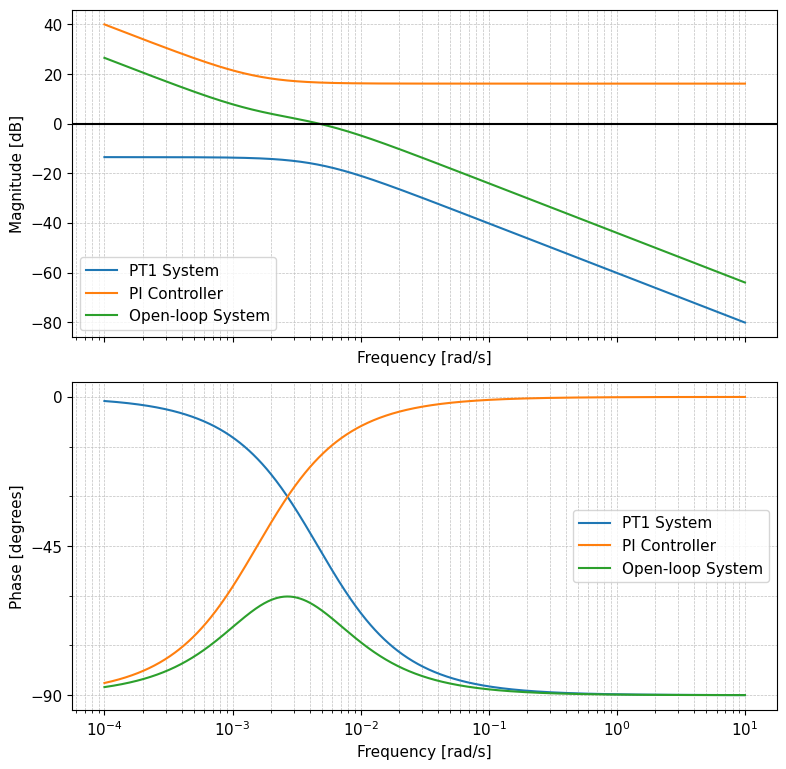

G_open = [873.57832701   1.3607139 ]
G_open = [[array([138640.84448043,    642.        ,      0.        ])]]
mag_open = [ 2.65404743e+01  2.64407426e+01  2.63410195e+01  2.62413051e+01
  2.61415997e+01  2.60419035e+01  2.59422166e+01  2.58425393e+01
  2.57428717e+01  2.56432143e+01  2.55435670e+01  2.54439303e+01
  2.53443044e+01  2.52446894e+01  2.51450856e+01  2.50454934e+01
  2.49459129e+01  2.48463444e+01  2.47467883e+01  2.46472447e+01
  2.45477141e+01  2.44481966e+01  2.43486926e+01  2.42492024e+01
  2.41497263e+01  2.40502646e+01  2.39508177e+01  2.38513859e+01
  2.37519696e+01  2.36525690e+01  2.35531847e+01  2.34538168e+01
  2.33544659e+01  2.32551322e+01  2.31558163e+01  2.30565185e+01
  2.29572391e+01  2.28579788e+01  2.27587377e+01  2.26595165e+01
  2.25603156e+01  2.24611353e+01  2.23619763e+01  2.22628389e+01
  2.21637238e+01  2.20646312e+01  2.19655619e+01  2.18665163e+01
  2.17674950e+01  2.16684984e+01  2.15695272e+01  2.14705820e+01
  2.13716633e+01  2.12727717e+01  2

In [41]:
# Define PT1 system transfer function
num_PT1 = [K]
den_PT1 = [T, 1]
G_PT1 = control.TransferFunction(num_PT1, den_PT1)
print(f"PT1: {G_PT1}")

# Define PI controller transfer function
num_PI = [Kp * Ti, Kp]
den_PI = [Ti, 0]
G_PI = control.TransferFunction(num_PI, den_PI)
print(f"PI: {G_PI}")

# Open-loop transfer function: G_open(s) = G_PT1(s) * G_PI(s)
G_open = G_PT1 * G_PI
print(f"Open-loop: {G_open}")

# Set up the frequency range for the Bode plot
omega = np.logspace(-4, 1, 1000)

# PLOT
fig, ax = plt.subplots(2, 1, figsize=(8, 8))

# Plot Bode plot of PT1 system
control.bode_plot(G_PT1, omega, dB=True, deg=True)
resp = control.frequency_response(G_PT1, omega)
mag = np.abs(resp.magnitude).squeeze()
mag_PT1 = 20 * np.log10(mag)
phase_PT1 = np.angle(resp.phase, deg=True).squeeze()


# Plot Bode plot of PI controller
control.bode_plot(G_PI, omega, dB=True, deg=True)
resp_PI = control.frequency_response(G_PI, omega)
mag = np.abs(resp_PI.magnitude).squeeze()
mag_PI = 20 * np.log10(mag)
phase_PI = np.angle(resp_PI.phase, deg=True).squeeze()

# Plot Bode plot of Open-loop system
control.bode_plot(G_open, omega, dB=True, deg=True)
resp_open = control.frequency_response(G_open, omega)
mag = np.abs(resp_open.magnitude).squeeze()
mag_open = 20 * np.log10(mag)
phase_open = np.angle(resp_open.phase, deg=True).squeeze()

ax[0].axhline(y=0, color='k', linestyle='-')
# ax[1].axhline(y=-180, color='k', linestyle='-')

ax[0].spines['bottom'].set_color('k')
ax[0].spines['left'].set_color('k')
ax[0].spines['right'].set_color('k')
ax[0].spines['top'].set_color('k')
ax[0].set_xlabel('Frequency [rad/s]')
ax[0].set_ylabel('Magnitude [dB]')
ax[0].legend(['PT1 System', 'PI Controller', 'Open-loop System'])
ax[0].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Configure phase plot
ax[1].spines['bottom'].set_color('k')
ax[1].spines['left'].set_color('k')
ax[1].spines['right'].set_color('k')
ax[1].spines['top'].set_color('k')
ax[1].set_xlabel('Frequency [rad/s]')
ax[1].set_ylabel('Phase [degrees]')
ax[1].legend(['PT1 System', 'PI Controller', 'Open-loop System'])
ax[1].grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)

# Adjust layout and show plot
plt.suptitle("") # remove titles
plt.tight_layout()
plt.show()

print(f"G_open = {G_open.num[0][0]}")
print(f"G_open = {G_open.den}")
print(f"mag_open = {mag_open}")

https://dynamics-and-control.readthedocs.io/en/latest/2_Control/4_Frequency_domain_analysis_of_control_systems/Frequency%20domain%20stability.html
##### Bode-Diagramm
* Phasenrand: Der Punkt, an dem die Verstärkung 0 dB beträgt, sollte betrachtet werden. Die Differenz zwischen -180° und der Phase an diesem Punkt ist der Phasenrand. Ein positiver Phasenrand von typischerweise mehr als 30° deutet auf ein stabiles System hin.
* Amplitudenrand: Der Punkt, an dem die Phase -180° beträgt, sollte betrachtet werden. Die Differenz zwischen 0 dB und der Verstärkung an diesem Punkt ist der Amplitudenrand. Ein negativer Amplitudenrand (d.h., die Verstärkung liegt unter 0 dB) deutet auf ein stabiles System hin.
##### Nyquist-Diagramm
* Umkreisung des Punktes -1+0j: Der Nyquist-Pfad sollte den Punkt $−1+0𝑗$ nicht umschließen. Wenn der Pfad den Punkt nicht umschließt, ist das System stabil.
* Anzahl der Umkreisungen: Falls es Umkreisungen gibt, zählt die Anzahl der Umkreisungen (im Uhrzeigersinn minus gegen den Uhrzeigersinn). Jede Umkreisung des Punktes $−1+0j$ in positiver Richtung weist auf eine Instabilität hin.

Phillipsen 2022:
S. 152-15 Kapitel 6.3 Stabilität

Stabilität heißt, dass...

Strebt die Sprungantwort des Systems einem endlichen Wert zu, ist das System stabil.

Vorraussetzung Stabilitätsanalyse ist die Kenntnis der Eigenwerte, also Nullstellen der charakteristischen Gleichung. Das System ist instabil, wenn ein Koeffizient der charakteristischen Gleichung null oder negativ ist. Ist eine Nullstelle null oder positiv, muss ein Koeffizient null oder negativ sein und somit das System instabil.

-----------------------------------------------------------
Magnitude Plot:
- shows the logarithmic magnitude (in dB) of the system's output relative to its input as a function of frequency

Phase Plot:
- indicates the phase shift of the system’s output relative to its input across different frequencies

Interpreting Bode Plots
- Magnitude Plot Interpretation: Look at peaks and dips to understand resonances and bandwidth. A flat response across desired frequencies often indicates good performance.
- Phase Plot Interpretation: Ensure phase shift does not exceed 180 degrees in feedback systems to avoid instability. Phase margin is crucial for stability.

[138640.84448043    642.              0.        ]
Pole =  [-0.00463067  0.        ]
<TransferFunction>: sys[108]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

     873.6 s + 1.361
  ---------------------
  1.386e+05 s^2 + 642 s
Pole =  [-0.00463067+0.j  0.        +0.j]
Nullstellen =  [-0.00155763+0.j]


c:\Users\dillin01\Documents\rotationalphantomtbme\.venv\Lib\site-packages\control\pzmap.py:327: FutureWarning: pole_zero_plot() return value of poles, zeros is deprecated; use pole_zero_map()
  warnings.warn(


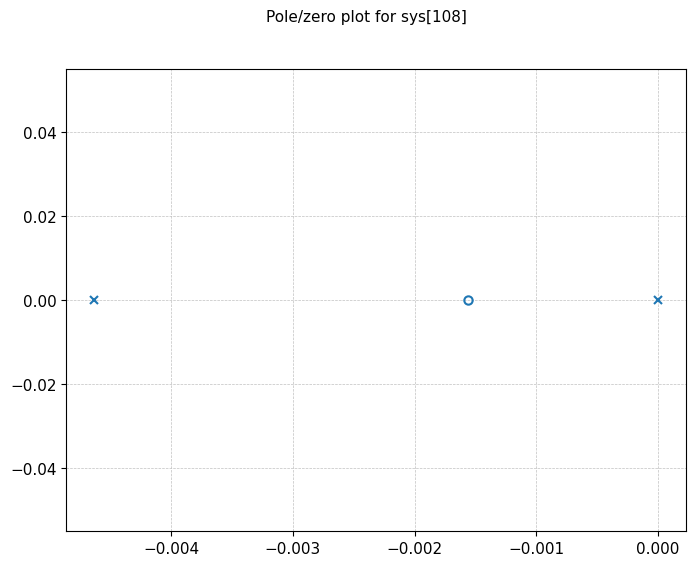

In [42]:
# Stabilitätsanalyse
import control.matlab as ma

num = G_open.num[0][0]
den  = G_open.den[0][0]
print(den)
print("Pole = ", str(np.roots(den)) )

# PLOT
fig4, ax4 = plt.subplots(1, 1, figsize=(8, 6))

sys = ma.tf(num,den)
print(sys)
print("Pole = ", ma.pole(sys) )
print("Nullstellen = ", ma.zero(sys) )
ma.pzmap(sys)

ax4.spines['bottom'].set_color('k')
ax4.spines['left'].set_color('k')
ax4.spines['right'].set_color('k')
ax4.spines['top'].set_color('k')
ax4.grid(True, which='both', color='silver', linestyle='--', linewidth=0.5)